# Building defect detector: finding cracks, mold, peeling paint and water damage in inspection photos

**Team 1:** Amelia, Jerome, Kazuko, Sahil
**Course:** AI Methods I – Day 4: Neural networks and computer vision (IAAC MaAI 2026/27)
**Track:** B (object detection), a YOLO26 detector fine-tuned on an openly licensed dataset
**Model on Hugging Face:** https://huggingface.co/iaac-maai/day4-team1-building-defect-detector

We fine-tune a YOLO26 detector to find five kinds of building defects, evaluate it honestly on a held-out test set, and then use it like a surveyor would: on **new photos** and on **videos** of walls (section 7), producing a ranked inspection report and annotated videos.

### Table of contents
0. Introduction and problem definition
1. Data and splits
2. Baselines
3. The model and its training
4. Look inside and diagnose
5. Tuning: one experiment
6. Test set, once
7. Application: new photos and videos
   - 7.1 An inspection report for new photos
   - 7.2 Video: the detector on a walk-through
8. Save, reload and use
9. Conclusions

# 0. Introduction and problem definition

On Day 2 we ranked New York buildings by the risk that their facade inspection comes back **UNSAFE**, so that inspections can be planned. Today we look at the next step: the **photos** taken during an inspection or a condition survey. A surveyor can come back from a building with hundreds of photos; going through them by hand to find and label every defect is slow.

### The three questions of the brief

| Question | Our answer |
|---|---|
| **Who would use this model, and for what?** | A building surveyor, facade inspector or facility manager who has **a folder of condition-survey photos or a walk-through video** (walls, ceilings, facades) and wants to know **which photos, or which moments of the video, show which defect**, so the ones to check first come to the top and the survey report can be prepared faster. The model **pre-screens**: a person always confirms. |
| **What does a mistake cost?** | A **missed defect** (false negative) is the expensive mistake: a crack or water infiltration that nobody looks at can grow into a structural or health problem (mold). A **false alarm** (false positive) only costs a few seconds of a person looking at a photo. We therefore favour **recall** and choose a low confidence threshold (section 6). |
| **What would be good enough?** | Better than the two baselines of section 2: the **pretrained YOLO** (which knows 80 everyday objects but no defects) and a **rule-based crack detector** with OpenCV (notebook 02). For a pre-screening tool, finding most defects (recall around 0.8) with a manageable number of false alarms would be useful. |

### The data

| | |
|---|---|
| **Dataset** | *detr_crack_dataset*, a Roboflow Universe project, mirrored on Hugging Face as [`senthilsk/crack_detection_dataset`](https://huggingface.co/datasets/senthilsk/crack_detection_dataset) |
| **Source** | [universe.roboflow.com/objectdetection-qxiqx/detr_crack_dataset](https://universe.roboflow.com/objectdetection-qxiqx/detr_crack_dataset) |
| **Licence** | CC BY 4.0 (allows derived models, with attribution) |
| **Size** | 2,950 images, 3,708 boxes, 5 classes: `crack`, `mold`, `peeling_paint`, `stairstep_crack`, `water_seepage` |
| **One example** | One photo of a wall or ceiling, with one box (x, y, width, height) and a class for every visible defect |

⚠️ **Provenance:** a few images carry watermarks of stock-photo and inspection websites, so the uploader probably collected some images from the web. The dataset is published under CC BY 4.0 by its uploader; we use it for a course assignment and report this as a limitation.

## 0.1 Setup

All paths are **relative** to the `notebook/` folder: data, figures and models live one level up, as the brief requires. Ultralytics writes its training runs to `runs/` (an absolute path, so they do not end up in a global folder) and the pretrained YOLO weights go to `data/weights/`. Both are ignored by git.

`TRAIN` is `True` when a GPU is available. Without a GPU the notebook downloads our published weights and training logs from Hugging Face and runs everything else.

In [1]:
# Only needed in Google Colab, Kaggle or a new environment: remove the "#" and run this cell once.
# %pip install -r ../requirements.txt

In [2]:
import os
os.environ["YOLO_VERBOSE"] = "False"     # keep Ultralytics' progress bars out of the notebook (results are printed below)

import json
import re
import shutil
import time
import zipfile
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
import yaml
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from ultralytics import SAM, YOLO, settings
from ultralytics.utils.downloads import attempt_download_asset
import ultralytics

C:\Users\User\group1_day4_assignment\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
RUNS_DIR = (Path("..") / "runs").resolve()            # Ultralytics training outputs (ignored by git)
WEIGHTS_DIR = (DATA_DIR / "weights").resolve()        # pretrained YOLO26 weights from Ultralytics (ignored by git)
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, WEIGHTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
settings.update({"weights_dir": str(WEIGHTS_DIR), "runs_dir": str(RUNS_DIR)})

RANDOM_STATE = 42
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
TRAIN = DEVICE == "cuda"          # False: use the weights we published on Hugging Face
RETRAIN = False                   # True: train again even if a finished run exists in runs/
HF_MODEL_REPO = "iaac-maai/day4-team1-building-defect-detector"
CLASS_NAMES = ["crack", "mold", "peeling_paint", "stairstep_crack", "water_seepage"]

sns.set_theme(style="whitegrid", context="notebook")
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.figsize"] = (10, 6)
print(f"PyTorch {torch.__version__}, Ultralytics {ultralytics.__version__}, device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("TRAIN =", TRAIN)


def save_fig(name, also_to_models=None):
    # Save the current figure to figures/ (and, for the model card, a copy to models/)
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=130, bbox_inches="tight")
    if also_to_models:
        plt.savefig(MODEL_DIR / f"{also_to_models}.png", dpi=130, bbox_inches="tight")
    print(f"Figure saved to {path}" + (f" and models/{also_to_models}.png" if also_to_models else ""))


def download(url, path, attempts=6):
    # Download a file once; servers such as Wikimedia ask clients to slow down (HTTP 429), so wait and retry
    path = Path(path)
    if path.exists():
        return path
    # Wikimedia asks for a descriptive User-Agent with a contact; Pexels only serves files to browser-like clients
    user_agent = ("IAAC-AI-Methods-course/1.0 (https://github.com/iaac-maai/group1_day4_assignment; educational use)"
                  if "wikimedia.org" in url else "Mozilla/5.0 (IAAC-AI-Methods-course/1.0; educational use)")
    for attempt in range(attempts):
        response = requests.get(url, headers={"User-Agent": user_agent}, timeout=300)
        if response.status_code in (429, 503) and attempt < attempts - 1:
            wait = int(response.headers.get("Retry-After", 0) or 0) or 15 * (attempt + 1)
            print(f"{path.name}: server busy ({response.status_code}), retrying in {wait} s")
            time.sleep(wait)
            continue
        response.raise_for_status()
        path.write_bytes(response.content)
        return path


# Privacy (notebook 02, section 7.1): the learned YuNet face detector. Every image shown in a figure is anonymised first.
YUNET_PATH = download("https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
                      DATA_DIR / "face_detection_yunet.onnx")
yunet = cv2.FaceDetectorYN.create(str(YUNET_PATH), "", (320, 320), score_threshold=0.6)


def find_faces(image):
    # Face boxes (x, y, w, h) found by YuNet
    yunet.setInputSize((image.shape[1], image.shape[0]))
    _, detections = yunet.detect(image)
    return [] if detections is None else detections[:, :4].astype(int)


def anonymise(image):
    # Blur every detected face (blur strength grows with face size)
    out = image.copy()
    for x, y, w, h in find_faces(image):
        x, y = max(0, x), max(0, y)
        if w > 0 and h > 0:
            out[y:y + h, x:x + w] = cv2.GaussianBlur(out[y:y + h, x:x + w], (0, 0), sigmaX=max(1, w / 4))
    return out


def show_image(image, title=None, ax=None, fontsize=11):
    # Show an OpenCV (BGR) image with matplotlib (RGB), with faces blurred
    ax = ax or plt.gca()
    ax.imshow(cv2.cvtColor(anonymise(image), cv2.COLOR_BGR2RGB))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=fontsize)

PyTorch 2.14.1+cu130, Ultralytics 8.4.190, device: cuda (NVIDIA GeForce RTX 5080 Laptop GPU)
TRAIN = True


# 1. Data and splits

## 1.1 Download

The dataset is downloaded from Hugging Face (about 46 MB, pinned to a fixed revision so everyone gets the same files) into `data/raw/`. The labels come in **COCO format** (one JSON file per split, boxes as x, y, width, height in pixels); we convert them to the YOLO format below.

In [4]:
DATASET_REPO = "senthilsk/crack_detection_dataset"
DATASET_REVISION = "03ae44b46cc85785201e625620a4b66bffe0f13a"
RAW_DIR = DATA_DIR / "raw"

for split in ["train", "valid", "test"]:
    target = RAW_DIR / split
    if not (target / "_annotations.coco.json").exists():
        zip_path = hf_hub_download(DATASET_REPO, f"data/{split}.zip", repo_type="dataset",
                                   revision=DATASET_REVISION, local_dir=RAW_DIR)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(target)

rows = []
for split in ["train", "valid", "test"]:
    coco = json.loads((RAW_DIR / split / "_annotations.coco.json").read_text())
    categories = {c["id"]: c["name"] for c in coco["categories"]}
    boxes = defaultdict(list)
    for a in coco["annotations"]:
        boxes[a["image_id"]].append((CLASS_NAMES.index(categories[a["category_id"]]), *a["bbox"]))
    for im in coco["images"]:
        rows.append({"file": RAW_DIR / split / im["file_name"], "original_split": split,
                     "width": im["width"], "height": im["height"], "boxes": boxes[im["id"]]})
images = pd.DataFrame(rows)
images["n_boxes"] = images["boxes"].map(len)

print(f"{len(images)} images, {images['n_boxes'].sum()} boxes")
print("Original split:", images["original_split"].value_counts().to_dict())
images["size"] = images["width"].astype(str) + " x " + images["height"].astype(str)
images["size"].value_counts().head(5)

2950 images, 3708 boxes
Original split: {'train': 2263, 'valid': 462, 'test': 225}


size
200 x 200    2131
227 x 227     250
612 x 408      71
259 x 194      48
275 x 183      36
Name: count, dtype: int64

## 1.2 Look at the data

### Class definitions

The notebook 03 checklist asks for classes **defined in writing**. The dataset comes without written rules, so these are our definitions, based on how the boxes are drawn in the images:

| ID | Class | What counts | What does not |
|---|---|---|---|
| 0 | `crack` | A visible fracture line in plaster, paint, render or concrete, of any direction or length; one box around the crack | Joints between tiles or panels, shadows, drawn lines |
| 1 | `mold` | Dark (black, green, grey) spotty growth on walls, ceilings or window frames, usually in corners or near windows | Uniform dirt or water stains without spots (see `water_seepage`) |
| 2 | `peeling_paint` | Paint or plaster that has lifted, flaked or fallen off, exposing the layer below | Intact paint of different colours |
| 3 | `stairstep_crack` | A crack in **masonry** (brick, block) that follows the mortar joints in a step pattern: a sign of settlement | Straight cracks through a plastered wall (`crack`) |
| 4 | `water_seepage` | Stains, tide marks or discoloured patches caused by water coming through a wall or ceiling | Mold spots growing on the stain (`mold`) |

The classes are **not exclusive in reality**: water causes stains, then mold and peeling paint, often in the same place. A photo can have boxes of several classes, and a box can be ambiguous.

### Privacy: are there people in the images?

The images show buildings, not people, but we check rather than assume: the YuNet face detector of notebook 02 runs over all 2,950 images. Every image shown in this notebook also goes through `anonymise()` (faces blurred) before it is drawn.

In [5]:
images_with_faces = [row.file.name for row in images.itertuples() if len(find_faces(cv2.imread(str(row.file))))]
print(f"YuNet found a face in {len(images_with_faces)} of {len(images)} images:", images_with_faces[:10])

YuNet found a face in 6 of 2950 images: ['images602_jpg.rf.faa09e3f230142d15b047b741b5f69b1.jpg', 'istockphoto-1094170854-612x612_jpg.rf.143fbcd878ac8fbf860dc37f8d300c9e.jpg', 'crack-repair2_jpg.rf.8bebd43440c8f5e6a32f7ab434cd4347.jpg', 'istockphoto-182357367-612x612_jpg.rf.0432e36f6341d3f2cc2881b4b9830b58.jpg', 'istockphoto-1071523466-612x612_jpg.rf.46fbeded0c5b855f3fbc85cba1274118.jpg', 'crack-1163-_jpg.rf.c4fad13a4fb826467974966646e380eb.jpg']


Below: one row per class, with the true boxes drawn.

Figure saved to ..\figures\01_dataset_examples.png and models/dataset_examples.png


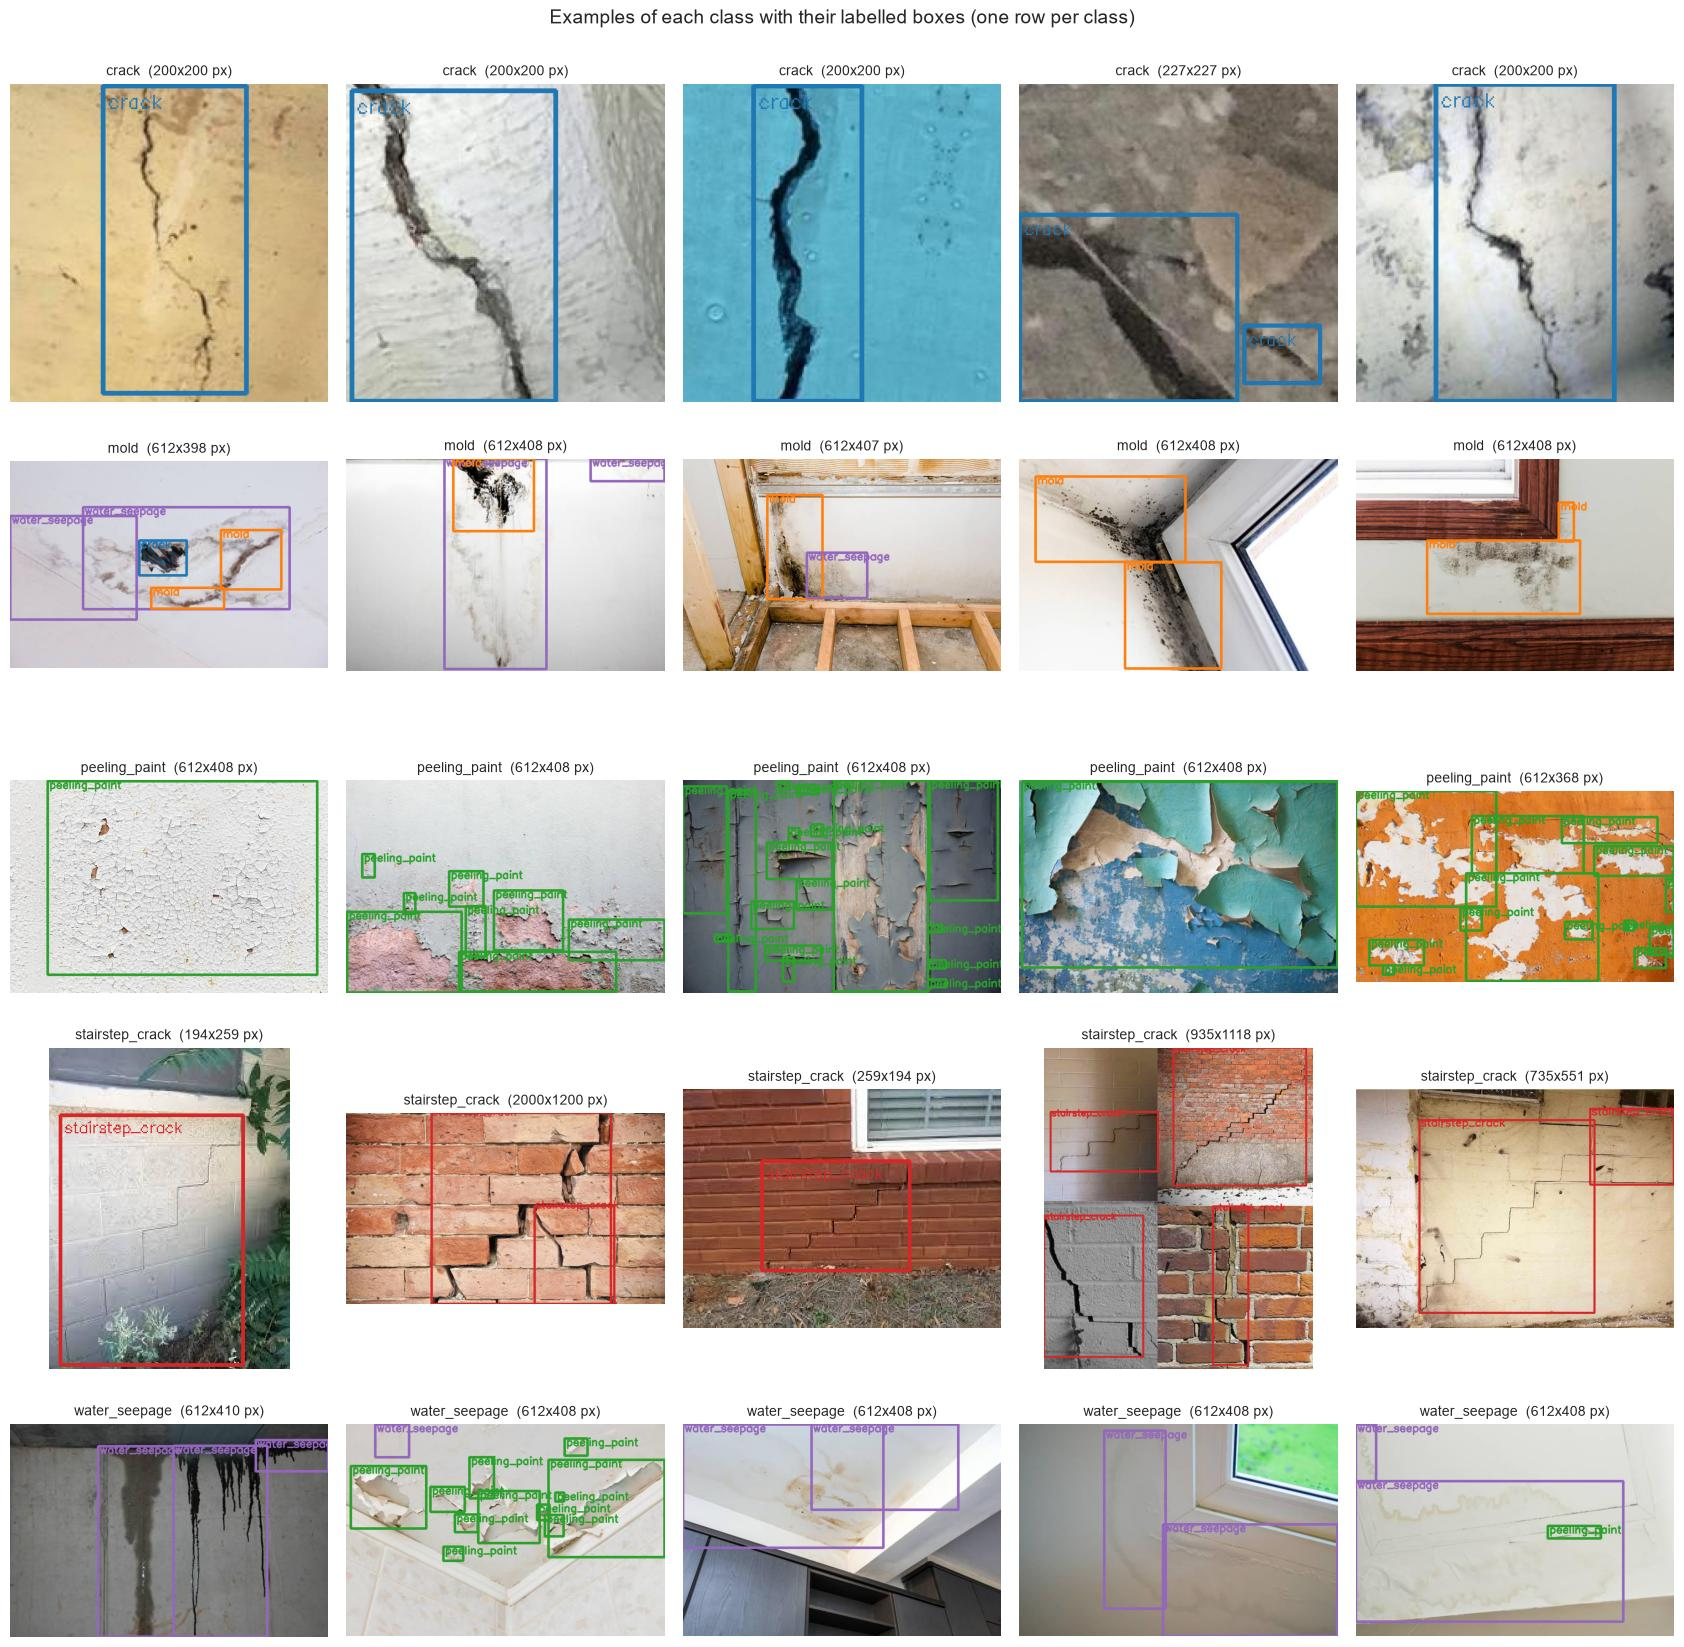

In [6]:
CLASS_COLORS = {i: tuple(int(255 * c) for c in plt.cm.tab10(i)[:3][::-1]) for i in range(len(CLASS_NAMES))}   # BGR


def truth_xyxy(boxes, cls=None):
    # COCO boxes (cls, x, y, w, h in pixels) -> list of (x1, y1, x2, y2), optionally of one class only
    return [(x, y, x + w, y + h) for c, x, y, w, h in boxes if cls is None or c == cls]


def draw_boxes(image, boxes, color=None, labels=True, thickness=None):
    # Draw COCO-style boxes (cls, x, y, w, h) on a copy of the image
    out = image.copy()
    thickness = thickness or max(2, out.shape[1] // 150)
    for c, x, y, w, h in boxes:
        col = color or CLASS_COLORS[c]
        cv2.rectangle(out, (int(x), int(y)), (int(x + w), int(y + h)), col, thickness)
        if labels:
            cv2.putText(out, CLASS_NAMES[c], (int(x) + 3, max(14, int(y) + 14)), cv2.FONT_HERSHEY_SIMPLEX,
                        max(0.4, out.shape[1] / 900), col, max(1, thickness // 2))
    return out


rng = np.random.default_rng(RANDOM_STATE)
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(17, 17))
for k, name in enumerate(CLASS_NAMES):
    with_class = images[images["boxes"].map(lambda b: any(c == k for c, *_ in b))]
    for ax, i in zip(axes[k], rng.choice(len(with_class), 5, replace=False)):
        row = with_class.iloc[i]
        image = cv2.imread(str(row["file"]))
        show_image(draw_boxes(image, row["boxes"]), f"{name}  ({row['width']}x{row['height']} px)", ax, 10)
plt.suptitle("Examples of each class with their labelled boxes (one row per class)", fontsize=14, y=1.0)
plt.tight_layout()
save_fig("01_dataset_examples", also_to_models="dataset_examples")
plt.show()

What we see:
- **Two kinds of images.** About 2,100 images are **small close-ups (200 × 200 or 227 × 227 px) of one crack** on a plain painted or concrete surface, with one box that covers most of the image. The other classes come from **larger photos of rooms, walls, ceilings and brick facades**, often with several boxes.
- **Class definitions overlap.** Mold, water seepage and peeling paint often appear together (water causes all three), and the boundary between a stain and mold is not always clear. A stair-step crack is a crack that follows the mortar joints of a masonry wall.
- **Boxes are loose.** A crack is a thin line, so its box contains mostly intact wall. The model has to learn that the line, not the wall, is the defect.

## 1.3 Split before anything else, by source

The dataset comes with its own train / valid / test split, but it is **not usable as it is**: the original test set contains **no `stairstep_crack` at all** and the validation set only one, so the model could never be evaluated on that class. We therefore pool all 2,950 images and **make our own split** (70 % / 15 % / 15 %), before looking at any result:

1. **By source.** Roboflow exports keep the original file name before `.rf.<hash>`. Images with the same original name, and images that are pixel-for-pixel near-identical (same 8 × 8 *average hash*), are put in one **group**, and a group always goes to a single split. Otherwise the test set could contain copies of training images.
2. **Stratified by the rarest class** in each group, so that every class appears in training, validation and test in about the same proportion.

The test set is then locked until section 6.

In [7]:
def average_hash(path):
    # 64-bit "average hash": a tiny grey thumbnail, thresholded at its mean. Near-identical images get the same hash.
    small = cv2.resize(cv2.imread(str(path), cv2.IMREAD_GRAYSCALE), (8, 8), interpolation=cv2.INTER_AREA)
    return (small > small.mean()).tobytes()


images["source_name"] = images["file"].map(lambda p: re.sub(r"_(jpe?g|png)\.rf\.[0-9a-f]+\.jpg$", "", p.name, flags=re.I))
images["hash"] = images["file"].map(average_hash)

# Union-find: images sharing a source name or a hash end up in the same group
parent = list(range(len(images)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for key in ["source_name", "hash"]:
    for members in images.groupby(key).indices.values():
        for j in members[1:]:
            parent[find(j)] = find(members[0])
images["group"] = [find(i) for i in range(len(images))]

# Stratification label: the rarest class in the group
box_counts = pd.Series([c for b in images["boxes"] for c, *_ in b]).value_counts()
rarity = {k: box_counts.get(k, 0) for k in range(len(CLASS_NAMES))}
images["rarest"] = images["boxes"].map(lambda b: min({c for c, *_ in b}, key=rarity.get) if b else 0)
group_label = images.groupby("group")["rarest"].agg(lambda s: min(s, key=rarity.get))

train_groups, rest_groups = train_test_split(group_label.index, test_size=0.30, stratify=group_label,
                                             random_state=RANDOM_STATE)
val_groups, test_groups = train_test_split(rest_groups, test_size=0.50, stratify=group_label[rest_groups],
                                           random_state=RANDOM_STATE)
split_of_group = {**{g: "train" for g in train_groups}, **{g: "val" for g in val_groups}, **{g: "test" for g in test_groups}}
images["split"] = images["group"].map(split_of_group)

print(f"{images['group'].nunique()} groups for {len(images)} images "
      f"({(images.groupby('group').size() > 1).sum()} groups contain more than one image)")
images["split"].value_counts().reindex(["train", "val", "test"])

2866 groups for 2950 images (61 groups contain more than one image)


split
train    2060
val       444
test      446
Name: count, dtype: int64

### Convert to the YOLO format

YOLO wants one text file per image with one line per box: `class x_centre y_centre width height`, all relative to the image size (0–1), and a YAML file with the folders and class names.

In [8]:
YOLO_DIR = (DATA_DIR / "defects_yolo").resolve()
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)                       # rebuilt from data/raw every time: always matches the split above
for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True)

for row in images.itertuples():
    shutil.copy(row.file, YOLO_DIR / "images" / row.split / row.file.name)
    lines = []
    for c, x, y, w, h in row.boxes:
        x1, y1 = max(0, x), max(0, y)
        x2, y2 = min(row.width, x + w), min(row.height, y + h)
        lines.append(f"{c} {(x1 + x2) / 2 / row.width:.6f} {(y1 + y2) / 2 / row.height:.6f} "
                     f"{(x2 - x1) / row.width:.6f} {(y2 - y1) / row.height:.6f}")
    (YOLO_DIR / "labels" / row.split / f"{row.file.stem}.txt").write_text("\n".join(lines))
images["yolo_image"] = [YOLO_DIR / "images" / s / f.name for s, f in zip(images["split"], images["file"])]

DATA_YAML = DATA_DIR / "defects.yaml"
DATA_YAML.write_text(yaml.safe_dump({"path": str(YOLO_DIR), "train": "images/train", "val": "images/val",
                                     "test": "images/test", "names": dict(enumerate(CLASS_NAMES))}, sort_keys=False))
print(DATA_YAML.read_text())
example = sorted((YOLO_DIR / "labels" / "train").glob("*.txt"))[0]
print(f"{example.name}:\n{example.read_text()}")

path: C:\Users\User\group1_day4_assignment\data\defects_yolo
train: images/train
val: images/val
test: images/test
names:
  0: crack
  1: mold
  2: peeling_paint
  3: stairstep_crack
  4: water_seepage

00002_jpg.rf.ff01e9d600aec5b2f27c2e60a9ae93ce.txt:
0 0.645374 0.497797 0.374449 0.995595


Figure saved to ..\figures\02_class_counts.png and models/class_counts.png


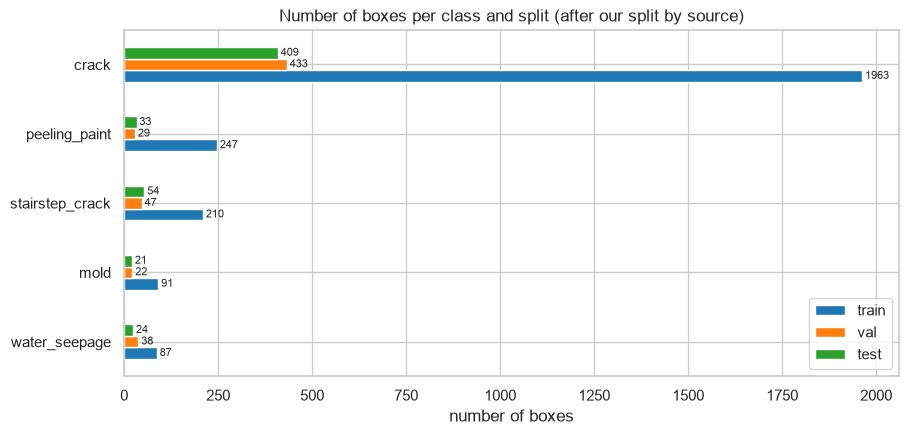

,train,val,test,images with this class
crack,1963,433,409,2591
mold,91,22,21,49
peeling_paint,247,29,33,70
stairstep_crack,210,47,54,249
water_seepage,87,38,24,58


In [9]:
counts = pd.DataFrame({split: pd.Series([CLASS_NAMES[c] for b in images.loc[images["split"] == split, "boxes"] for c, *_ in b])
                       .value_counts() for split in ["train", "val", "test"]}).reindex(CLASS_NAMES).fillna(0).astype(int)
counts["images with this class"] = [images["boxes"].map(lambda b: any(c == k for c, *_ in b)).sum() for k in range(len(CLASS_NAMES))]

ax = counts[["train", "val", "test"]].sort_values("train").plot.barh(figsize=(10, 4.5), color=["tab:blue", "tab:orange", "tab:green"])
for container in ax.containers:
    ax.bar_label(container, fontsize=8, padding=2)
plt.title("Number of boxes per class and split (after our split by source)")
plt.xlabel("number of boxes")
plt.ylabel("")
save_fig("02_class_counts", also_to_models="class_counts")
plt.show()
counts

**Reading:** the data is **very imbalanced**: about 70 % of all boxes are `crack`, while `mold` and `water_seepage` have only about 100–150 boxes in total, i.e. only about **20 boxes each in the test set**. Per-class results for the rare classes will therefore be noisy (one image more or less changes the score by several points), and we expect them to be learned less well.

# 2. Baselines

Before training, two reference points:

1. **The pretrained YOLO26s, without fine-tuning.** It was trained on COCO (80 everyday object classes). Does it already find anything useful in our photos?
2. **A rule-based crack detector** in the spirit of notebook 02: cracks are thin **dark lines** on a lighter surface. A *black-hat* morphological filter highlights thin dark structures, Otsu's threshold turns them into a mask, and the box around the largest connected dark structure is our "crack". This only works for the `crack` class.

To measure both, we use the same rule as YOLO's metrics: a predicted box is a **true positive** if it has the right class and an **IoU ≥ 0.5** with a true box (greedy matching, most confident first).

In [10]:
def iou(a, b):
    # Intersection over union of two boxes (x1, y1, x2, y2)
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0


def match_counts(pred_boxes, true_boxes, iou_threshold=0.5):
    # Greedy matching of predictions (sorted by confidence) to true boxes: (true positives, false positives, false negatives)
    matched, tp = set(), 0
    for p in pred_boxes:
        best = max(((iou(p, t), j) for j, t in enumerate(true_boxes) if j not in matched), default=(0, None))
        if best[0] >= iou_threshold:
            matched.add(best[1])
            tp += 1
    return tp, len(pred_boxes) - tp, len(true_boxes) - tp


def rule_based_crack(image):
    # Box around the largest thin dark structure, or None
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    scale = 320 / max(gray.shape)
    small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    small = cv2.GaussianBlur(small, (5, 5), 0)
    blackhat = cv2.morphologyEx(small, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17)))
    _, mask = cv2.threshold(blackhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n <= 1:
        return None
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    if stats[k, cv2.CC_STAT_AREA] < 0.002 * mask.size:
        return None
    x, y, w, h = stats[k, :4] / scale
    return (x, y, x + w, y + h)


def rule_based_scores(split):
    # Precision and recall of the rule-based detector for the crack class on one split
    tp = fp = fn = 0
    for row in images[images["split"] == split].itertuples():
        box = rule_based_crack(cv2.imread(str(row.yolo_image)))
        counts_ = match_counts([box] if box is not None else [], truth_xyxy(row.boxes, cls=0))
        tp, fp, fn = tp + counts_[0], fp + counts_[1], fn + counts_[2]
    return {"precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "found": tp, "false alarms": fp, "missed": fn}


attempt_download_asset(str(WEIGHTS_DIR / "yolo26s.pt"))   # pretrained weights (COCO), downloaded once
attempt_download_asset(str(WEIGHTS_DIR / "yolo26n.pt"))
pretrained = YOLO(str(WEIGHTS_DIR / "yolo26s.pt"))
print(f"The pretrained model knows {len(pretrained.names)} COCO classes. Defect classes among them:",
      [n for n in pretrained.names.values() if n in CLASS_NAMES] or "none")

rule_val = rule_based_scores("val")
print(f"Rule-based crack detector on the validation set: precision {rule_val['precision']:.2f}, recall {rule_val['recall']:.2f} "
      f"({rule_val['found']} found, {rule_val['false alarms']} false alarms, {rule_val['missed']} missed)")

The pretrained model knows 80 COCO classes. Defect classes among them: none


Rule-based crack detector on the validation set: precision 0.39, recall 0.40 (173 found, 271 false alarms, 260 missed)


Figure saved to ..\figures\03_baselines.png


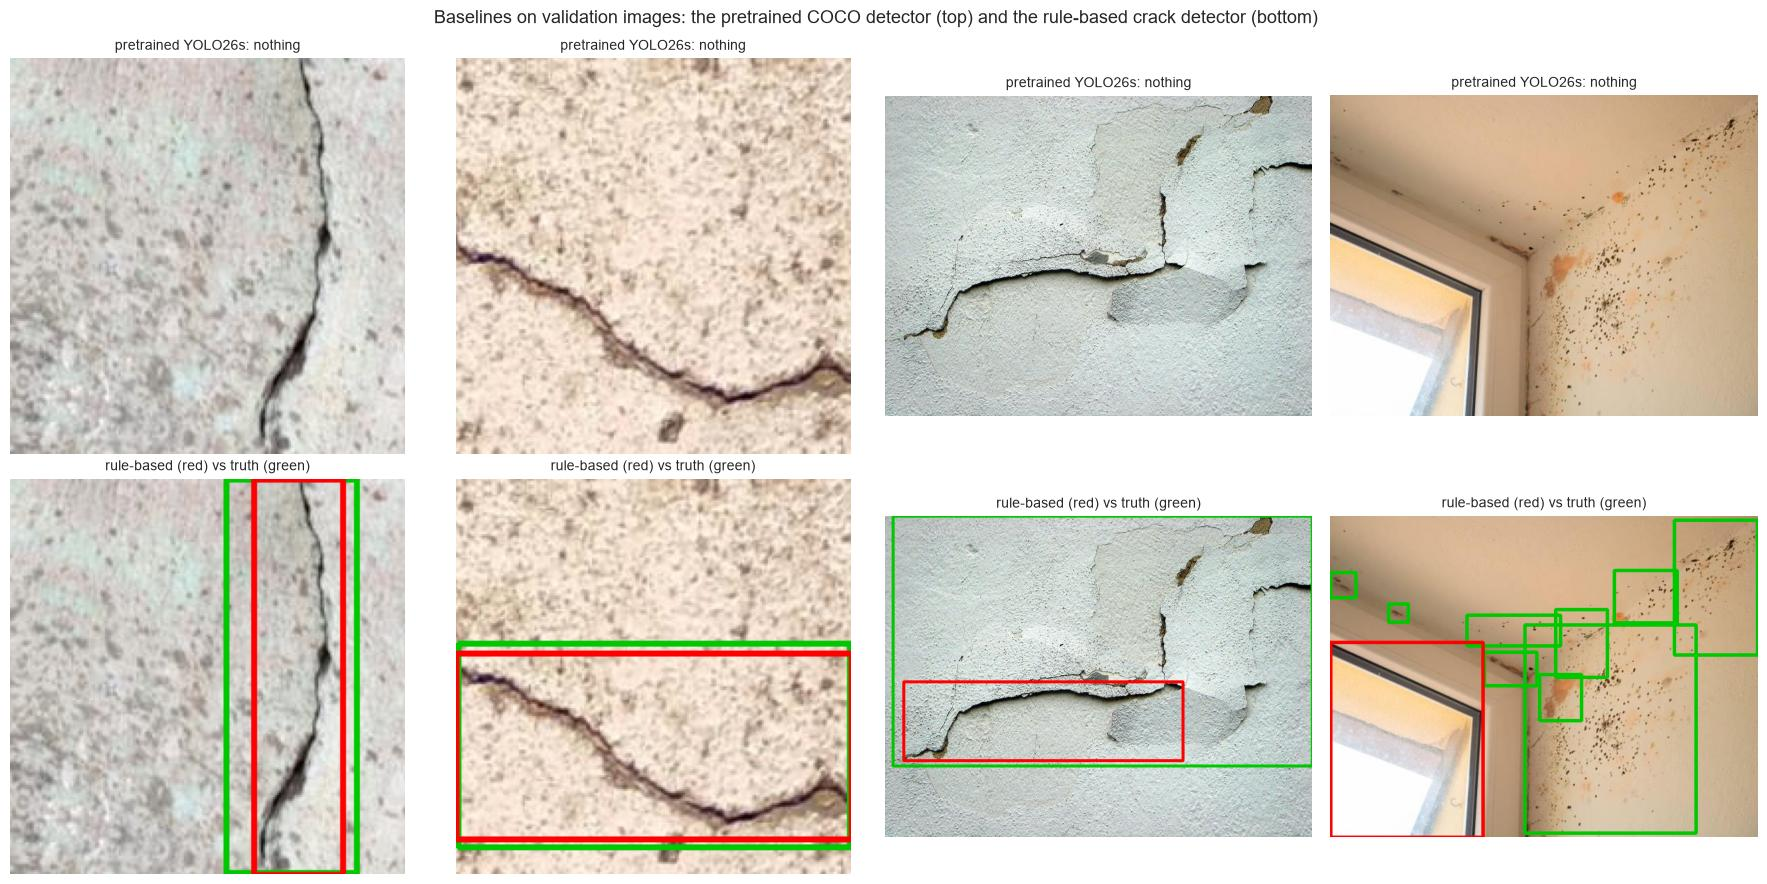

In [11]:
val_images = images[images["split"] == "val"].reset_index(drop=True)
picks = [val_images[val_images["boxes"].map(lambda b, k=k: any(c == k for c, *_ in b))].iloc[0] for k in [0, 0, 2, 1]]
picks[1] = val_images[val_images["boxes"].map(lambda b: any(c == 0 for c, *_ in b))].iloc[7]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, row in enumerate(picks):
    image = cv2.imread(str(row["yolo_image"]))
    result = pretrained.predict(image, conf=0.25, device=DEVICE, verbose=False)[0]
    found = ", ".join(sorted({pretrained.names[int(c)] for c in result.boxes.cls})) or "nothing"
    show_image(result.plot(line_width=2), f"pretrained YOLO26s: {found}", axes[0, col], 10)
    out = draw_boxes(image, row["boxes"], color=(0, 200, 0), labels=False)
    box = rule_based_crack(image)
    if box is not None:
        cv2.rectangle(out, (int(box[0]), int(box[1])), (int(box[2]), int(box[3])), (0, 0, 255), max(2, out.shape[1] // 150))
    show_image(out, "rule-based (red) vs truth (green)", axes[1, col], 10)
plt.suptitle("Baselines on validation images: the pretrained COCO detector (top) and the rule-based crack detector (bottom)",
             fontsize=13)
plt.tight_layout()
save_fig("03_baselines")
plt.show()

**Reading:** the pretrained YOLO26s finds **nothing** in any of the four photos: none of its 80 COCO classes is a building defect, so its score on our task is 0 by construction. Its learned features (edges, textures, shapes) are still useful: that is what fine-tuning reuses. The rule-based detector works when the crack is the darkest thin line on a plain wall (first two images), but it has no idea *what* a crack is: on the mold photo it boxes the **window frame**, a dark straight edge. On the whole validation set it reaches a precision of **0.39** and a recall of **0.40** for cracks (173 found, 271 false alarms, 260 missed). These are the numbers to beat.

# 3. The model and its training

We fine-tune **YOLO26s** (small, about 10 M parameters), pretrained on COCO. One call loads the pretrained weights, replaces the 80-class head with a new **5-class head** and trains on our images, with YOLO's built-in augmentation (flips, colour changes, scaling, mosaics of 4 images).

| Setting | Value | Why |
|---|---|---|
| Model | `yolo26s.pt` | A good balance of speed and accuracy on a laptop GPU (notebook 03) |
| `epochs` | 60 | Enough for the validation mAP to level off (see the curves) |
| `patience` | 20 | Early stopping: stop if validation mAP has not improved for 20 epochs |
| `imgsz` | 640 | Images are resized to 640 px; section 5 tests 320 px |
| `batch` | 32 | Fits easily in the 16 GB of the GPU |
| `seed` | 42 | Reproducible |

**Training tier:** local, on a laptop **NVIDIA RTX 5080 (16 GB)**. Without a GPU, `TRAIN = False` downloads our weights and training log from Hugging Face instead.

In [12]:
EXPERIMENTS = {                                   # section 5 compares these on the validation set
    "yolo26s_640": {"model": "yolo26s.pt", "imgsz": 640},
    "yolo26n_640": {"model": "yolo26n.pt", "imgsz": 640},
    "yolo26s_320": {"model": "yolo26s.pt", "imgsz": 320},
}
MAIN_RUN = "yolo26s_640"
EPOCHS, BATCH, PATIENCE = 60, 32, 20


def train_run(name):
    # Train one configuration (or reuse a finished run); returns the path of its best weights and its training time
    run_dir = RUNS_DIR / name
    best = run_dir / "weights" / "best.pt"
    time_file = run_dir / "training_minutes.txt"
    if best.exists() and time_file.exists() and not RETRAIN:
        print(f"{name}: reusing the finished run in {run_dir} (set RETRAIN = True to train again)")
        return best, float(time_file.read_text())
    config = EXPERIMENTS[name]
    start = time.time()
    model = YOLO(str(WEIGHTS_DIR / config["model"]))
    model.train(data=str(DATA_YAML.resolve()), epochs=EPOCHS, imgsz=config["imgsz"], batch=BATCH, patience=PATIENCE,
                device=0, seed=RANDOM_STATE, deterministic=True, project=str(RUNS_DIR), name=name, exist_ok=True,
                workers=4, verbose=False, plots=True)
    minutes = (time.time() - start) / 60
    time_file.write_text(f"{minutes:.1f}")
    print(f"{name}: training took {minutes:.1f} minutes")
    return best, minutes


if TRAIN:
    main_weights, main_minutes = train_run(MAIN_RUN)
    main_results_csv = RUNS_DIR / MAIN_RUN / "results.csv"
else:
    hf_dir = DATA_DIR / "hf_model"
    main_weights = Path(hf_hub_download(HF_MODEL_REPO, "model.pt", local_dir=hf_dir))
    main_results_csv = Path(hf_hub_download(HF_MODEL_REPO, "results.csv", local_dir=hf_dir))
    main_minutes = float("nan")
    print(f"No GPU: using the published model https://huggingface.co/{HF_MODEL_REPO}")

detector = YOLO(main_weights)
print("Classes:", detector.names)
print(f"Parameters: {sum(p.numel() for p in detector.model.parameters()):,}")

yolo26s_640: reusing the finished run in C:\Users\User\group1_day4_assignment\runs\yolo26s_640 (set RETRAIN = True to train again)
Classes: {0: 'crack', 1: 'mold', 2: 'peeling_paint', 3: 'stairstep_crack', 4: 'water_seepage'}
Parameters: 9,951,734


Figure saved to ..\figures\04_training_curves.png and models/training_curves.png


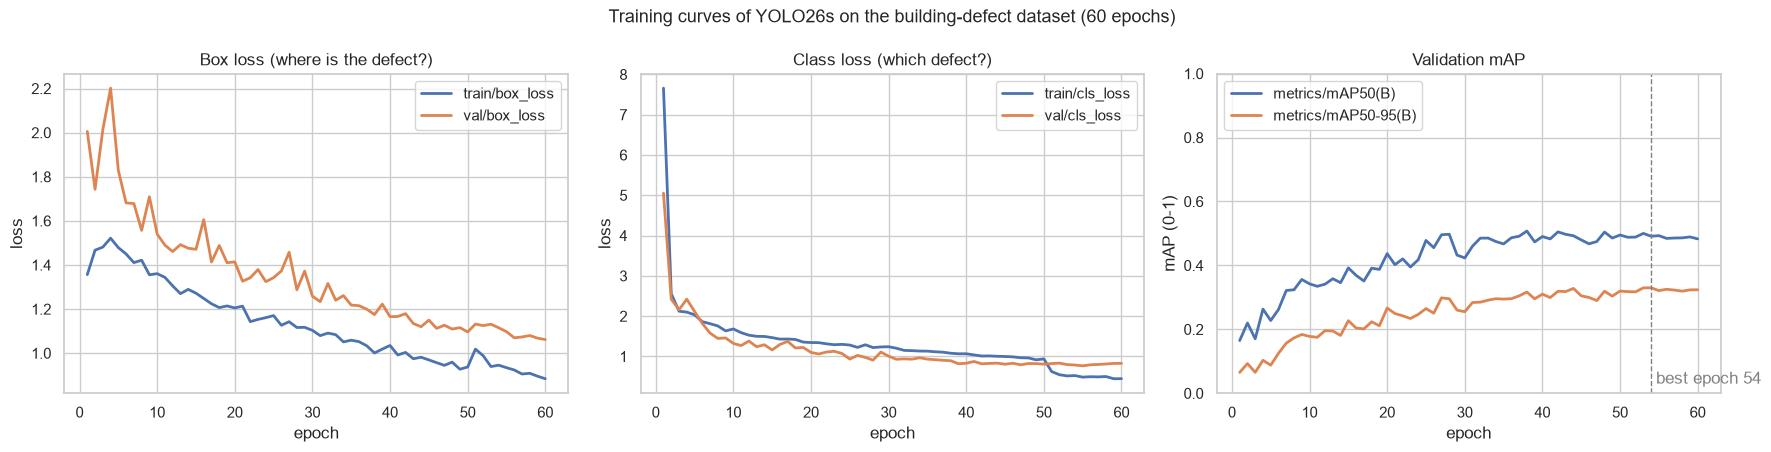

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
0,1,0.431,0.160,0.165,0.065
4,5,0.653,0.185,0.228,0.088
15,16,0.651,0.325,0.369,0.204
30,31,0.548,0.438,0.460,0.284
45,46,0.581,0.448,0.468,0.300
59,60,0.571,0.482,0.483,0.324


In [13]:
history = pd.read_csv(main_results_csv)
history.columns = history.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (cols, title, ylabel) in zip(axes, [
        (["train/box_loss", "val/box_loss"], "Box loss (where is the defect?)", "loss"),
        (["train/cls_loss", "val/cls_loss"], "Class loss (which defect?)", "loss"),
        (["metrics/mAP50(B)", "metrics/mAP50-95(B)"], "Validation mAP", "mAP (0-1)")]):
    history.plot(x="epoch", y=cols, ax=ax, lw=2, title=title)
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
axes[2].set_ylim(0, 1)
best_epoch = int(history.loc[history["metrics/mAP50-95(B)"].idxmax(), "epoch"])
axes[2].axvline(best_epoch, color="grey", ls="--", lw=1)
axes[2].text(best_epoch, 0.03, f" best epoch {best_epoch}", color="grey")
plt.suptitle(f"Training curves of YOLO26s on the building-defect dataset ({len(history)} epochs)", fontsize=13)
plt.tight_layout()
save_fig("04_training_curves", also_to_models="training_curves")
plt.show()
rows_to_show = sorted({0, 4, len(history) // 4, len(history) // 2, 3 * len(history) // 4, len(history) - 1})
history[["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].iloc[rows_to_show].round(3)

**Reading (main run, YOLO26s):**
- **Transfer learning starts fast:** the validation mAP50 is 0.17 after one epoch, 0.37 after 16 and 0.46 after 31, then levels off around **0.48–0.50** from epoch 40 (best mAP50-95 **0.33**, at epoch 54, whose weights are kept).
- **No real overfitting:** both validation losses keep falling with the training losses until the end. The box loss is higher on validation than on training, but the gap stays about the same.
- **The plateau** after about epoch 40 says that more epochs would gain little: the limit is the data (few examples of the rare classes and inconsistent boxes, see section 4), not the training time.
- The sudden drop of the training class loss at epoch 51 is the end of the mosaic augmentation (`close_mosaic=10`): the last 10 epochs see plain, easier images.
- The validation curve is noisy from one epoch to the next (for example around epochs 28–31): a few images of the rare classes move the mean over five classes.

# 4. Look inside and diagnose

On the **validation** set (the test set stays locked): per-class scores, the confusion matrix, and a gallery of the mistakes.

In [14]:
val_metrics = detector.val(data=str(DATA_YAML.resolve()), split="val", device=DEVICE, project=str(RUNS_DIR),
                           name=f"{MAIN_RUN}_val", exist_ok=True, verbose=False, plots=True)
per_class_val = pd.DataFrame({"boxes": counts["val"], "precision": val_metrics.box.p, "recall": val_metrics.box.r,
                              "AP50": val_metrics.box.ap50, "AP50-95": val_metrics.box.ap}, index=CLASS_NAMES).round(3)
print(f"VALIDATION: mAP50 = {val_metrics.box.map50:.3f}, mAP50-95 = {val_metrics.box.map:.3f}")
per_class_val.sort_values("AP50")

VALIDATION: mAP50 = 0.494, mAP50-95 = 0.331


,boxes,precision,recall,AP50,AP50-95
water_seepage,38,0.353,0.105,0.208,0.134
mold,22,0.434,0.227,0.227,0.120
peeling_paint,29,0.391,0.310,0.345,0.200
stairstep_crack,47,0.841,0.809,0.768,0.531
crack,433,0.909,0.882,0.924,0.672


Figure saved to ..\figures\05_confusion_matrix_val.png


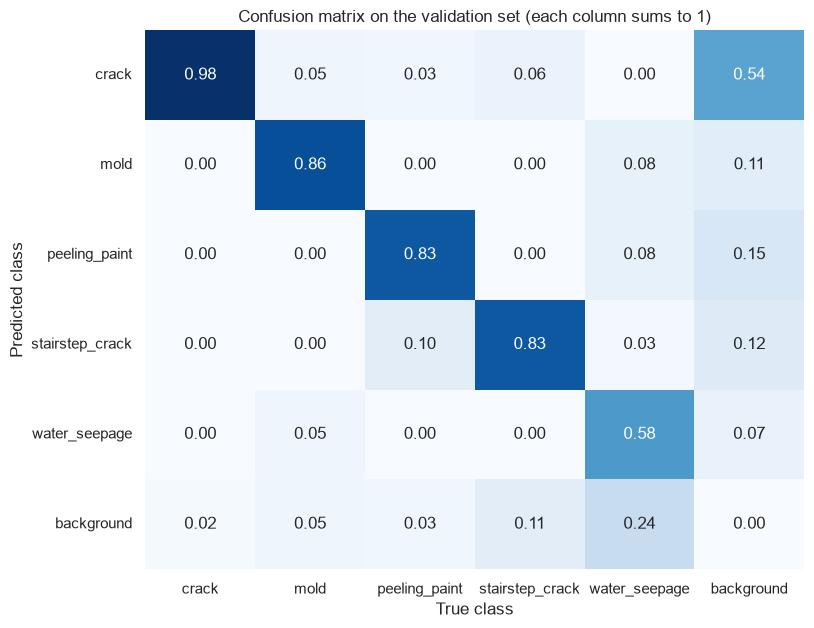

,true crack,true mold,true peeling_paint,true stairstep_crack,true water_seepage,true background
pred crack,424,1,1,3,0,3296
pred mold,0,19,0,0,3,675
pred peeling_paint,1,0,24,0,3,945
pred stairstep_crack,1,0,3,39,1,761
pred water_seepage,0,1,0,0,22,428
pred background,7,1,1,5,9,0


In [15]:
def plot_confusion(metrics, title, name, also_to_models=None):
    # Column-normalised confusion matrix: each true class (column) sums to 1; last row/column = background
    matrix = metrics.confusion_matrix.matrix
    labels = CLASS_NAMES + ["background"]
    normalised = matrix / matrix.sum(axis=0, keepdims=True).clip(min=1)
    plt.figure(figsize=(8.5, 7))
    sns.heatmap(normalised, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False)
    plt.xlabel("True class")
    plt.ylabel("Predicted class")
    plt.title(title)
    save_fig(name, also_to_models)
    plt.show()
    return pd.DataFrame(matrix.astype(int), index=[f"pred {l}" for l in labels], columns=[f"true {l}" for l in labels])


plot_confusion(val_metrics, "Confusion matrix on the validation set (each column sums to 1)", "05_confusion_matrix_val")

**Reading (validation set, main run YOLO26s):** the classes fall into two groups.
- **Line defects are learned well:** `crack` AP50 **0.92** (precision 0.91, recall 0.88) and `stairstep_crack` **0.77**: many examples and a clear, consistent shape.
- **Surface defects are weak:** `peeling_paint` 0.35, `mold` 0.23 and `water_seepage` 0.21, with recall between 0.11 and 0.31. They have few examples (22–38 boxes in validation, 87–247 in training) and fuzzy, overlapping definitions.
- **The confusion matrix** (detections at confidence ≥ 0.25 matched with IoU ≥ 0.45) shows that a matched surface defect usually gets the **right** label (diagonal 0.58–0.86): confusions *between* classes are small. The problems are the bottom row (missed: 24 % of the water seepage, 11 % of the stair-step cracks) and the right-hand column: **54 % of all false alarms are `crack`**, the class the model sees most often.

### Gallery of failures (validation set)

We predict every validation image at a confidence of 0.25 and match the predictions to the true boxes per class (IoU ≥ 0.5). Then we show the images with the most **missed defects** (false negatives) and the most confident **false alarms** (false positives). Green = truth, red = prediction.

Figure saved to ..\figures\06_failures_val.png and models/failures.png


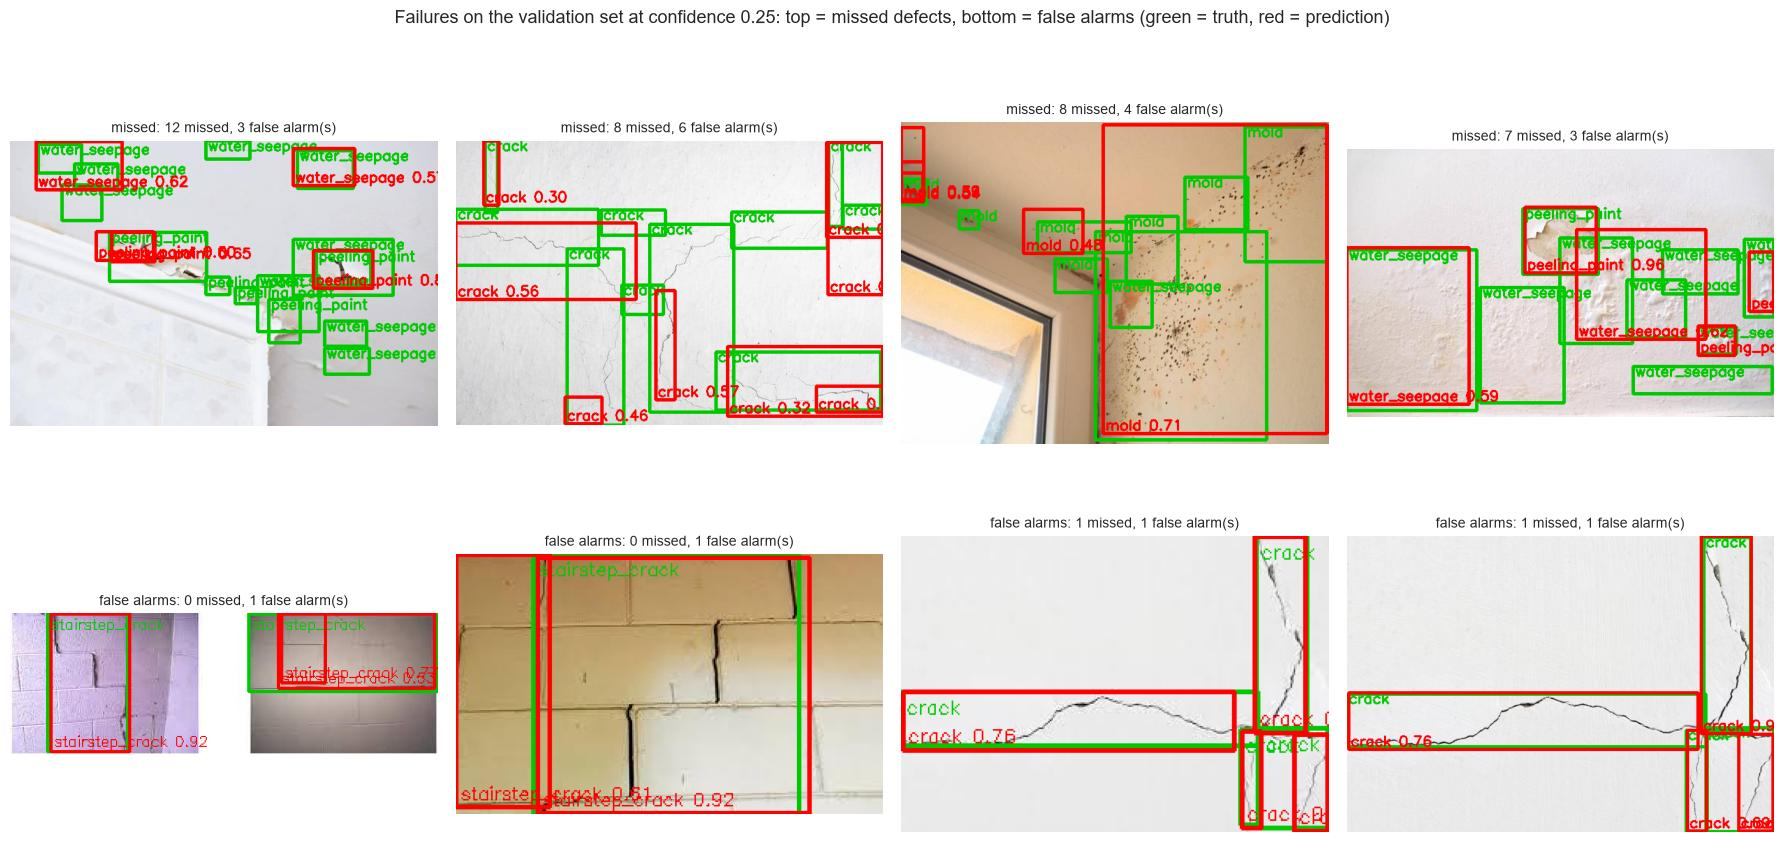

At 0.25: 128 of 569 true boxes missed, 109 false alarms in 444 validation images


In [16]:
def predict_split(model, split, conf=0.01):
    # Predict every image of a split once, at a low threshold; returns {path: (xyxy, classes, confidences)}
    out = {}
    paths = list(images.loc[images["split"] == split, "yolo_image"])
    for start in range(0, len(paths), 64):
        for path, result in zip(paths[start:start + 64],
                                model.predict([str(p) for p in paths[start:start + 64]], conf=conf, device=DEVICE, verbose=False)):
            out[path] = (result.boxes.xyxy.cpu().numpy(), result.boxes.cls.cpu().numpy().astype(int), result.boxes.conf.cpu().numpy())
    return out


def per_image_errors(predictions, split, threshold):
    # One row per image: missed true boxes and false alarms (all classes), at a given threshold
    rows = []
    for row in images[images["split"] == split].itertuples():
        boxes, classes, confidences = predictions[row.yolo_image]
        fn = fp = 0
        fp_conf = 0.0
        for k in range(len(CLASS_NAMES)):
            keep = (classes == k) & (confidences >= threshold)
            order = np.argsort(-confidences[keep])
            tp_, fp_, fn_ = match_counts(boxes[keep][order], truth_xyxy(row.boxes, cls=k))
            fn, fp = fn + fn_, fp + fp_
            if fp_:
                fp_conf = max(fp_conf, confidences[keep].max())
        rows.append({"image": row.yolo_image, "true boxes": row.n_boxes, "missed": fn, "false alarms": fp, "max false-alarm conf": fp_conf})
    return pd.DataFrame(rows)


def draw_prediction(image, boxes, classes, confidences, threshold, color=(0, 0, 255)):
    out = image.copy()
    t = max(2, out.shape[1] // 150)
    for (x1, y1, x2, y2), c, p in zip(boxes, classes, confidences):
        if p >= threshold:
            cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), color, t)
            cv2.putText(out, f"{CLASS_NAMES[c]} {p:.2f}", (int(x1) + 3, int(y2) - 5), cv2.FONT_HERSHEY_SIMPLEX,
                        max(0.4, out.shape[1] / 900), color, max(1, t // 2))
    return out


def failure_gallery(predictions, split, threshold, title, name, also_to_models=None):
    errors = per_image_errors(predictions, split, threshold)
    missed = errors[errors["missed"] > 0].sort_values(["missed", "true boxes"], ascending=False).head(4)
    false_alarms = errors[(errors["false alarms"] > 0) & ~errors["image"].isin(missed["image"])] \
        .sort_values("max false-alarm conf", ascending=False).head(4)
    fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
    for ax_row, (subset, kind) in zip(axes, [(missed, "missed"), (false_alarms, "false alarms")]):
        for ax, (_, row) in zip(ax_row, subset.iterrows()):
            truth = images.loc[images["yolo_image"] == row["image"], "boxes"].iloc[0]
            image = draw_boxes(cv2.imread(str(row["image"])), truth, color=(0, 200, 0))
            show_image(draw_prediction(image, *predictions[row["image"]], threshold),
                       f"{kind}: {row['missed']} missed, {row['false alarms']} false alarm(s)", ax, 10)
        for ax in ax_row[len(subset):]:
            ax.set_axis_off()
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    save_fig(name, also_to_models)
    plt.show()
    return errors


val_predictions = predict_split(detector, "val")
val_errors = failure_gallery(val_predictions, "val", 0.25,
                             "Failures on the validation set at confidence 0.25: top = missed defects, bottom = false alarms "
                             "(green = truth, red = prediction)", "06_failures_val", also_to_models="failures")
print(f"At 0.25: {val_errors['missed'].sum()} of {val_errors['true boxes'].sum()} true boxes missed, "
      f"{val_errors['false alarms'].sum()} false alarms in {len(val_errors)} validation images")

**What the failures have in common:**
- **Many small boxes against a few large ones.** The images with the most missed defects (top row) are photos of rooms and walls where the annotator drew **many small boxes** (12 patches of water seepage and peeling paint; 8 separate pieces of one crack network), while the model draws a few larger boxes over the same area. With the IoU ≥ 0.5 rule, one large box over three small true boxes counts as 1 false alarm and 3 misses, although a person would call it correct. The labelling of surface defects is **not consistent in size**: one stain is one box in one image and five boxes in another.
- **Scattered mold spots** (third image): the model finds the dense area, but not every small cluster that was labelled separately.
- **Many 'false alarms' are duplicates or different splits of a real defect** (bottom row): two boxes on one stair-step crack (0.92 and 0.51), or a crack network split into boxes differently from the labels. False alarms on intact wall are rarer.
- So the low scores of the surface classes are partly a **labelling** problem (ambiguous box extent), not only a model problem. For pre-screening ('is there water damage in this photo?') the model is more useful than its AP suggests; for counting or measuring individual defects it is not reliable.

# 5. Tuning: one experiment

We change **one thing at a time** compared with the main run (YOLO26s, 640 px) and compare on the **validation** set:

| Run | Change | Question |
|---|---|---|
| `yolo26s_640` | — (main run) | |
| `yolo26n_640` | model size: **nano** (about 2.5 M parameters) instead of small | Is a 4× smaller, faster model good enough? |
| `yolo26s_320` | image size: **320 px** instead of 640 | Most images are only 200–227 px wide: does upscaling to 640 help, or just cost time? |

The final model is the run with the best **validation mAP50-95**.

yolo26s_640: reusing the finished run in C:\Users\User\group1_day4_assignment\runs\yolo26s_640 (set RETRAIN = True to train again)


yolo26n_640: reusing the finished run in C:\Users\User\group1_day4_assignment\runs\yolo26n_640 (set RETRAIN = True to train again)


yolo26s_320: reusing the finished run in C:\Users\User\group1_day4_assignment\runs\yolo26s_320 (set RETRAIN = True to train again)


Figure saved to ..\figures\07_experiments.png


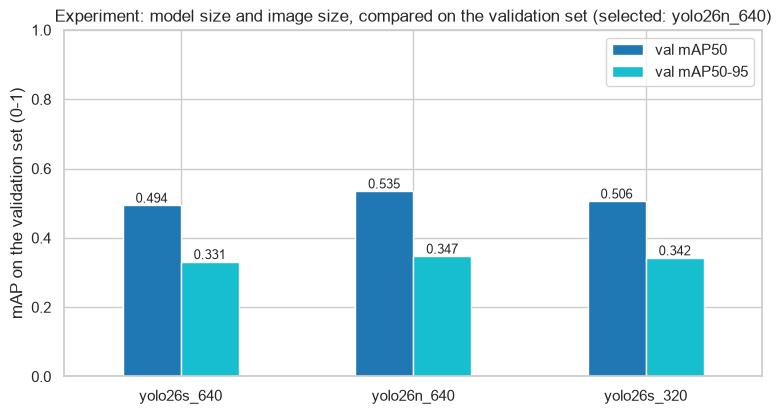

Selected run: yolo26n_640


,model,image size,parameters (M),epochs trained,training (min),inference (ms/img),val precision,val recall,val mAP50,val mAP50-95
run,,,,,,,,,,
yolo26s_640,yolo26s.pt,640,10.0,60,24.5,2.8,0.586,0.467,0.494,0.331
yolo26n_640,yolo26n.pt,640,2.5,60,11.7,2.0,0.633,0.526,0.535,0.347
yolo26s_320,yolo26s.pt,320,10.0,60,7.3,1.9,0.610,0.484,0.506,0.342


In [17]:
experiment_rows = []
if TRAIN:
    for name in EXPERIMENTS:
        weights, minutes = train_run(name)
        model = YOLO(weights)
        m = model.val(data=str(DATA_YAML.resolve()), split="val", device=DEVICE, project=str(RUNS_DIR),
                      name=f"{name}_val", exist_ok=True, verbose=False, plots=False)
        experiment_rows.append({"run": name, "model": EXPERIMENTS[name]["model"], "image size": EXPERIMENTS[name]["imgsz"],
                                "parameters (M)": round(sum(p.numel() for p in model.model.parameters()) / 1e6, 1),
                                "epochs trained": len(pd.read_csv(RUNS_DIR / name / "results.csv")),
                                "training (min)": round(minutes, 1), "inference (ms/img)": round(m.speed["inference"], 1),
                                "val precision": round(m.box.mp, 3), "val recall": round(m.box.mr, 3),
                                "val mAP50": round(m.box.map50, 3), "val mAP50-95": round(m.box.map, 3)})
    experiments = pd.DataFrame(experiment_rows).set_index("run")
    experiments.to_csv(MODEL_DIR / "experiments.csv")
else:
    experiments = pd.read_csv(hf_hub_download(HF_MODEL_REPO, "experiments.csv", local_dir=DATA_DIR / "hf_model")).set_index("run")

FINAL_RUN = experiments["val mAP50-95"].idxmax()
ax = experiments[["val mAP50", "val mAP50-95"]].plot.bar(figsize=(9, 4.5), rot=0, color=["tab:blue", "tab:cyan"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=9)
plt.title(f"Experiment: model size and image size, compared on the validation set (selected: {FINAL_RUN})")
plt.ylabel("mAP on the validation set (0-1)")
plt.xlabel("")
plt.ylim(0, 1)
save_fig("07_experiments")
plt.show()
print("Selected run:", FINAL_RUN)
experiments

**Reading:** the **smallest model wins**.
- YOLO26n (2.4 M parameters) reaches a validation mAP50-95 of **0.347**, against 0.331 for YOLO26s (10 M parameters) with the same 640 px images. It trains in half the time (11.7 against 24.5 minutes) and predicts faster. With about 2,000 training images, mostly simple close-ups, the larger model has more capacity than the data can use.
- **320 px images** (0.342) are as good as 640 px with the same YOLO26s, and 3× faster to train (7.3 minutes): logical, since about 2,400 of the 2,950 images are only 200–227 px wide, and enlarging them to 640 px adds no information.
- The differences (0.01–0.02 mAP) are about as large as the noise between epochs, so the honest conclusion is that **model size and image size barely matter here: the data does**. We select **YOLO26n at 640 px** (best validation mAP50-95); the 320 px model would have been an equally reasonable, even faster choice.
- Sections 3–4 showed the main run (YOLO26s); **from section 6 on, all results are for the selected YOLO26n.**

# 6. Test set, once

The test set has not been used for any decision so far. We now evaluate the selected model on it **once**: mAP50 and mAP50-95 overall and per class, precision and recall, the confusion matrix, the comparison with the baselines, and the choice of the confidence threshold.

In [18]:
if TRAIN:
    final_weights = RUNS_DIR / FINAL_RUN / "weights" / "best.pt"
    final_results_csv = RUNS_DIR / FINAL_RUN / "results.csv"
else:
    final_weights, final_results_csv = main_weights, main_results_csv      # the published model is the selected one
final = YOLO(final_weights)

test_metrics = final.val(data=str(DATA_YAML.resolve()), split="test", device=DEVICE, project=str(RUNS_DIR),
                         name=f"{FINAL_RUN}_test", exist_ok=True, verbose=False, plots=True)
per_class_test = pd.DataFrame({"boxes in test set": counts["test"], "precision": test_metrics.box.p,
                               "recall": test_metrics.box.r, "AP50": test_metrics.box.ap50,
                               "AP50-95": test_metrics.box.ap}, index=CLASS_NAMES).round(3)
print(f"TEST SET ({FINAL_RUN}): mAP50 = {test_metrics.box.map50:.3f}, mAP50-95 = {test_metrics.box.map:.3f}, "
      f"precision = {test_metrics.box.mp:.3f}, recall = {test_metrics.box.mr:.3f}")
per_class_test

TEST SET (yolo26n_640): mAP50 = 0.464, mAP50-95 = 0.297, precision = 0.524, recall = 0.456


,boxes in test set,precision,recall,AP50,AP50-95
crack,409,0.832,0.922,0.931,0.691
mold,21,0.463,0.286,0.292,0.183
peeling_paint,33,0.145,0.121,0.049,0.022
stairstep_crack,54,0.775,0.704,0.765,0.467
water_seepage,24,0.407,0.250,0.285,0.120


Figure saved to ..\figures\08_per_class_ap.png and models/per_class_ap.png


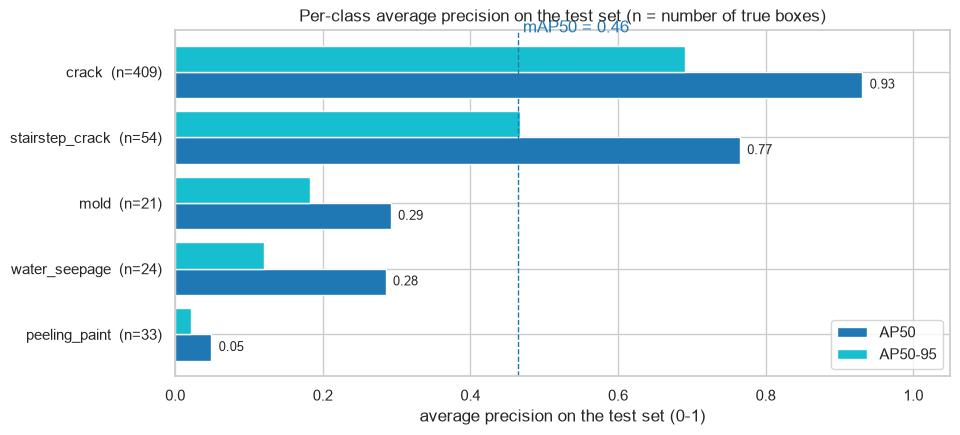

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = per_class_test.sort_values("AP50").index
y = np.arange(len(order))
ax.barh(y - 0.2, per_class_test.loc[order, "AP50"], 0.4, label="AP50", color="tab:blue")
ax.barh(y + 0.2, per_class_test.loc[order, "AP50-95"], 0.4, label="AP50-95", color="tab:cyan")
ax.set_yticks(y, [f"{c}  (n={per_class_test.loc[c, 'boxes in test set']})" for c in order])
for i, c in enumerate(order):
    ax.text(per_class_test.loc[c, "AP50"] + 0.01, i - 0.2, f"{per_class_test.loc[c, 'AP50']:.2f}", va="center", fontsize=9)
ax.axvline(test_metrics.box.map50, color="tab:blue", ls="--", lw=1)
ax.text(test_metrics.box.map50, len(order) - 0.4, f" mAP50 = {test_metrics.box.map50:.2f}", color="tab:blue")
ax.set_xlim(0, 1.05)
ax.set_xlabel("average precision on the test set (0-1)")
ax.set_title("Per-class average precision on the test set (n = number of true boxes)")
ax.legend(loc="lower right")
save_fig("08_per_class_ap", also_to_models="per_class_ap")
plt.show()

Figure saved to ..\figures\09_confusion_matrix_test.png and models/confusion_matrix.png


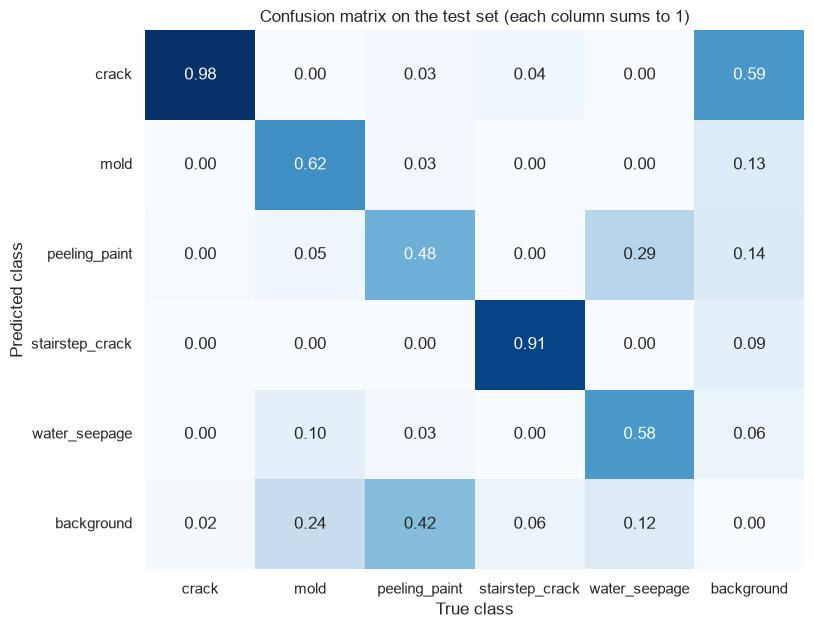

,true crack,true mold,true peeling_paint,true stairstep_crack,true water_seepage,true background
pred crack,400,0,1,2,0,4316
pred mold,0,13,1,0,0,930
pred peeling_paint,2,1,16,0,7,991
pred stairstep_crack,0,0,0,49,0,669
pred water_seepage,0,2,1,0,14,404
pred background,7,5,14,3,3,0


In [20]:
plot_confusion(test_metrics, "Confusion matrix on the test set (each column sums to 1)", "09_confusion_matrix_test",
               also_to_models="confusion_matrix")

### Comparison with the baselines

The rule-based detector only finds cracks and the pretrained model finds no defect class at all, so the fair comparison for the **crack class** is precision and recall at IoU ≥ 0.5. For all classes, only our model has a non-zero score.

In [21]:
test_predictions = predict_split(final, "test")


def sweep(predictions, split, thresholds):
    # Precision and recall per class and pooled over all classes, at several confidence thresholds
    rows = []
    for threshold in thresholds:
        totals = np.zeros(3, dtype=int)
        for k, name in enumerate(CLASS_NAMES):
            tp = fp = fn = 0
            for row in images[images["split"] == split].itertuples():
                boxes, classes, confidences = predictions[row.yolo_image]
                keep = (classes == k) & (confidences >= threshold)
                order_ = np.argsort(-confidences[keep])
                c_ = match_counts(boxes[keep][order_], truth_xyxy(row.boxes, cls=k))
                tp, fp, fn = tp + c_[0], fp + c_[1], fn + c_[2]
            totals += [tp, fp, fn]
            rows.append({"class": name, "threshold": threshold, "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                         "found": tp, "false alarms": fp, "missed": fn})
        tp, fp, fn = totals
        rows.append({"class": "all classes", "threshold": threshold, "precision": tp / max(tp + fp, 1),
                     "recall": tp / max(tp + fn, 1), "found": tp, "false alarms": fp, "missed": fn})
    out = pd.DataFrame(rows)
    out["F2"] = 5 * out["precision"] * out["recall"] / (4 * out["precision"] + out["recall"]).clip(lower=1e-9)
    return out


THRESHOLDS = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7]
val_sweep = sweep(val_predictions if FINAL_RUN == MAIN_RUN else predict_split(final, "val"), "val", THRESHOLDS)
test_sweep = sweep(test_predictions, "test", THRESHOLDS)

# The threshold is CHOSEN on the validation set (max F2: recall counts twice as much as precision), then checked on test
pooled_val = val_sweep[val_sweep["class"] == "all classes"].set_index("threshold")
RECOMMENDED_THRESHOLD = float(pooled_val["F2"].idxmax())

rule_test = rule_based_scores("test")
crack_test = test_sweep[(test_sweep["class"] == "crack") & (test_sweep["threshold"] == RECOMMENDED_THRESHOLD)].iloc[0]
all_test = test_sweep[(test_sweep["class"] == "all classes") & (test_sweep["threshold"] == RECOMMENDED_THRESHOLD)].iloc[0]
comparison = pd.DataFrame([
    {"model": "Pretrained YOLO26s (COCO, no fine-tuning)", "crack precision": 0.0, "crack recall": 0.0,
     "all-class recall": 0.0, "mAP50 (all classes)": 0.0},
    {"model": "Rule-based crack detector (OpenCV)", "crack precision": rule_test["precision"], "crack recall": rule_test["recall"],
     "all-class recall": rule_test["found"] / counts["test"].sum(), "mAP50 (all classes)": float("nan")},
    {"model": f"Our fine-tuned {FINAL_RUN} (conf {RECOMMENDED_THRESHOLD})", "crack precision": crack_test["precision"],
     "crack recall": crack_test["recall"], "all-class recall": all_test["recall"], "mAP50 (all classes)": test_metrics.box.map50},
]).set_index("model").round(3)
comparison

,crack precision,crack recall,all-class recall,mAP50 (all classes)
model,,,,
"Pretrained YOLO26s (COCO, no fine-tuning)",0.000,0.000,0.000,0.000
Rule-based crack detector (OpenCV),0.413,0.450,0.340,NaN
Our fine-tuned yolo26n_640 (conf 0.15),0.713,0.919,0.808,0.464


### Choosing the confidence threshold

A missed defect costs more than a false alarm (section 0), so we choose the threshold that maximises the **F2 score** on the **validation** set: like F1, but recall counts twice as much as precision. Choosing it on validation and only *reporting* it on test keeps the test set honest.

Figure saved to ..\figures\10_threshold_sweep.png and models/threshold_sweep.png


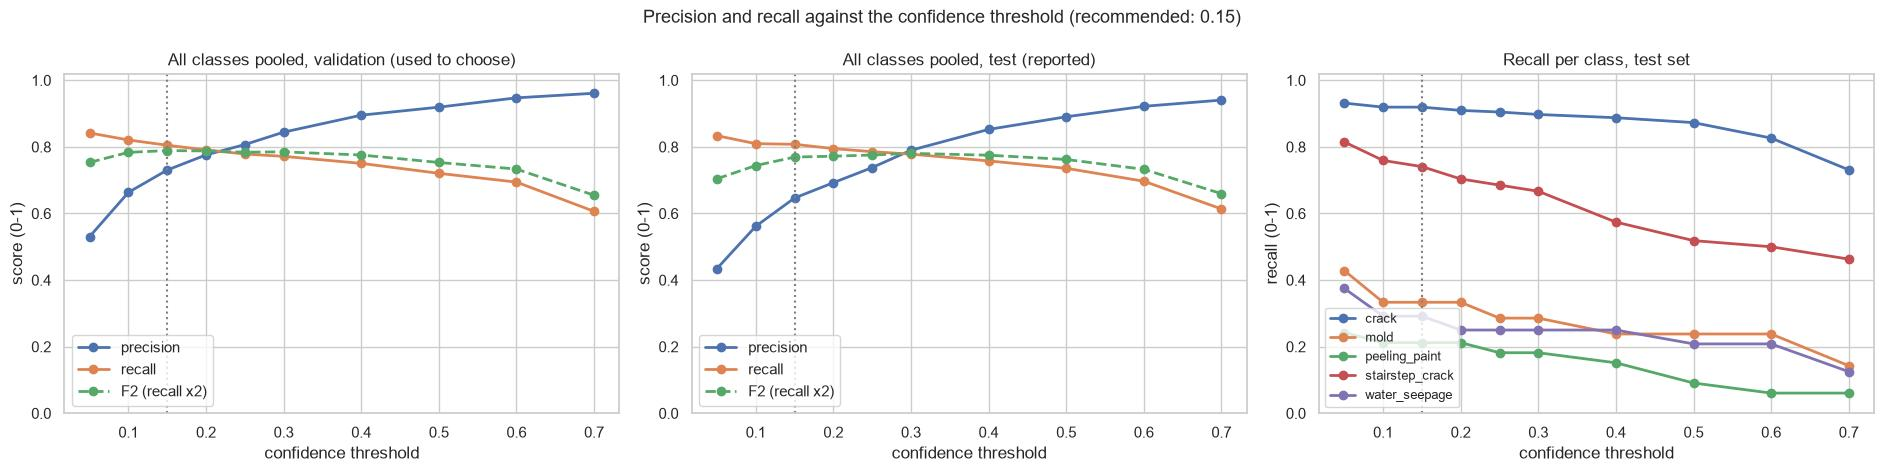

Recommended threshold: 0.15


,threshold,precision,recall,found,false alarms,missed,F2
class,,,,,,,
crack,0.15,0.71,0.92,376,151,33,0.87
mold,0.15,0.32,0.33,7,15,14,0.33
peeling_paint,0.15,0.17,0.21,7,35,26,0.20
stairstep_crack,0.15,0.60,0.74,40,27,14,0.71
water_seepage,0.15,0.39,0.29,7,11,17,0.31
all classes,0.15,0.65,0.81,437,239,104,0.77


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, (data, title) in zip(axes[:2], [(val_sweep, "validation (used to choose)"), (test_sweep, "test (reported)")]):
    pooled = data[data["class"] == "all classes"]
    ax.plot(pooled["threshold"], pooled["precision"], marker="o", lw=2, label="precision")
    ax.plot(pooled["threshold"], pooled["recall"], marker="o", lw=2, label="recall")
    ax.plot(pooled["threshold"], pooled["F2"], marker="o", lw=2, ls="--", label="F2 (recall x2)")
    ax.axvline(RECOMMENDED_THRESHOLD, color="grey", ls=":")
    ax.set_title(f"All classes pooled, {title}")
    ax.set_xlabel("confidence threshold")
    ax.set_ylabel("score (0-1)")
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower left")
for name in CLASS_NAMES:
    part = test_sweep[test_sweep["class"] == name]
    axes[2].plot(part["threshold"], part["recall"], marker="o", lw=2, label=name)
axes[2].axvline(RECOMMENDED_THRESHOLD, color="grey", ls=":")
axes[2].set_title("Recall per class, test set")
axes[2].set_xlabel("confidence threshold")
axes[2].set_ylabel("recall (0-1)")
axes[2].set_ylim(0, 1.02)
axes[2].legend(loc="lower left", fontsize=9)
plt.suptitle(f"Precision and recall against the confidence threshold (recommended: {RECOMMENDED_THRESHOLD})", fontsize=13)
plt.tight_layout()
save_fig("10_threshold_sweep", also_to_models="threshold_sweep")
plt.show()
print("Recommended threshold:", RECOMMENDED_THRESHOLD)
test_sweep[test_sweep["threshold"] == RECOMMENDED_THRESHOLD].set_index("class").round(2)

### Predictions next to the truth (test set)

One test image per class, chosen at random (seed 42), at the recommended threshold. Top: the true boxes; bottom: the predictions with their confidence.

Figure saved to ..\figures\11_predictions_vs_truth.png and models/predictions_vs_truth.png


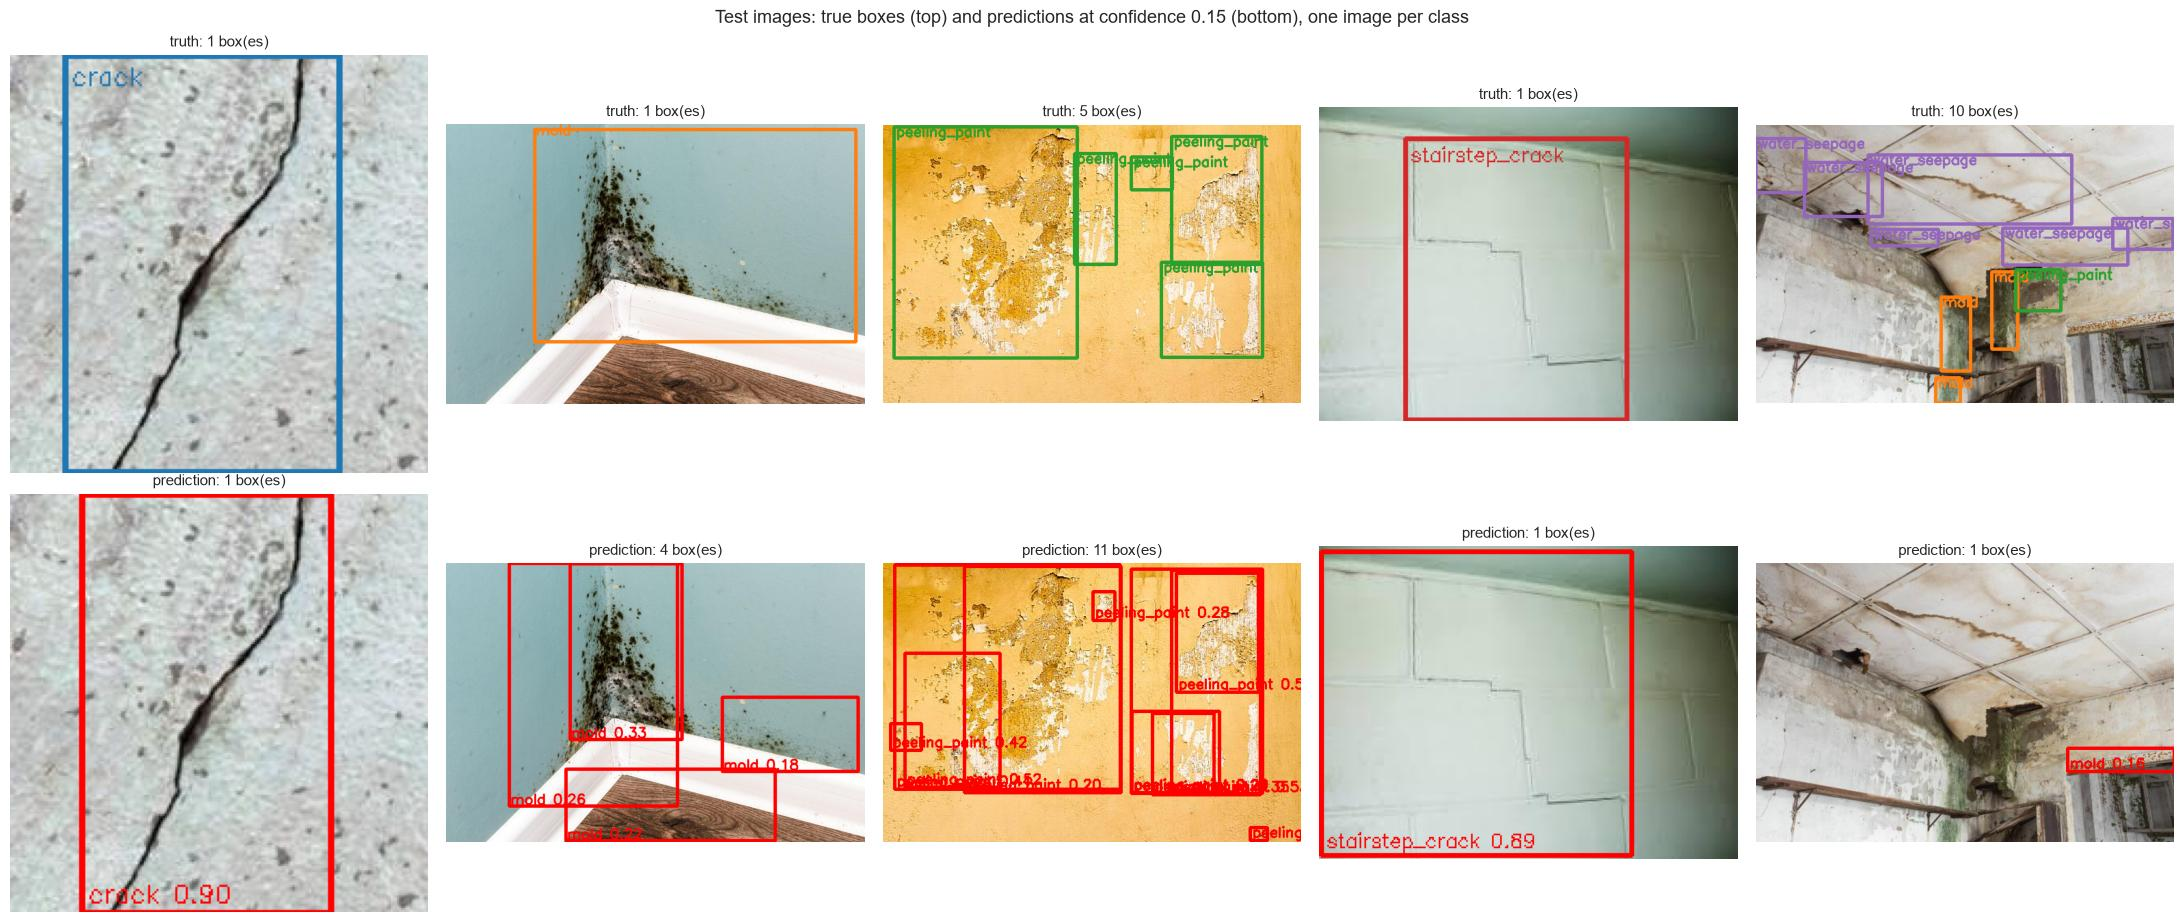

In [23]:
test_images = images[images["split"] == "test"]
rng = np.random.default_rng(RANDOM_STATE)
fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(22, 9.5))
for col, k in enumerate(range(len(CLASS_NAMES))):
    candidates = test_images[test_images["boxes"].map(lambda b: any(c == k for c, *_ in b))]
    row = candidates.iloc[rng.integers(len(candidates))]
    image = cv2.imread(str(row["yolo_image"]))
    show_image(draw_boxes(image, row["boxes"]), f"truth: {row['n_boxes']} box(es)", axes[0, col], 11)
    boxes, classes, confidences = test_predictions[row["yolo_image"]]
    n = int((confidences >= RECOMMENDED_THRESHOLD).sum())
    show_image(draw_prediction(image, boxes, classes, confidences, RECOMMENDED_THRESHOLD), f"prediction: {n} box(es)", axes[1, col], 11)
plt.suptitle(f"Test images: true boxes (top) and predictions at confidence {RECOMMENDED_THRESHOLD} (bottom), one image per class",
             fontsize=13)
plt.tight_layout()
save_fig("11_predictions_vs_truth", also_to_models="predictions_vs_truth")
plt.show()

**Reading (test set, 446 images, used once; model YOLO26n):**
- **Overall:** mAP50 **0.46** and mAP50-95 **0.30** (validation: 0.54 and 0.35). Slightly lower than on validation, as expected for data that influenced no choice.
- **Per class, the same two groups:** `crack` (AP50 **0.93**) and `stairstep_crack` (**0.77**) are reliable; `mold` (0.29), `water_seepage` (0.28) and `peeling_paint` (**0.05**) are not. Peeling paint is the weakest class on the test set: 42 % of its boxes are missed, and 29 % of the water-seepage boxes are labelled as peeling paint: both are stains with flaking paint, and they are labelled inconsistently. The rare classes have only 21–33 test boxes, so their scores are uncertain by about ±0.1.
- **Against the baselines (cracks):** at the recommended threshold the model finds **92 %** of the cracks with a precision of **0.71**, against 45 % and 0.41 for the rule-based detector and nothing for the pretrained model. Over all classes it finds **81 %** of the defects (rule-based: 34 %, cracks only).
- **Confidence threshold: 0.15**, chosen on the validation set as the maximum of F2. On the test set: recall **0.81**, precision **0.65** (437 defects found, 239 false alarms, 104 missed). A threshold of 0.3 would balance both at about 0.78, but for pre-screening, where a missed defect costs more than a look at a photo, we recommend **0.15**. For the surface classes no threshold gives a good recall (mold at most 0.43, even at 0.05): only more and better-labelled data will help.
- **Predictions next to the truth:** the crack and the stair-step crack are found exactly; the mold corner is found, but split into 4 boxes (1 true box); peeling paint is found everywhere, in 11 boxes against 5; in the room with 10 water-seepage boxes the model sees only one patch of mold: the typical miss.

# 7. Application: new photos and videos

The model is finished and tested. Now we **use** it on material it has never seen and that has no labels: eight photos (7.1) and three videos (7.2). These are not used for training or scoring; they show how the model behaves in practice, including its mistakes.

## 7.1 An inspection report for new photos

The real use case: a surveyor's folder of photos the model has **never seen**, from other buildings and cameras. We use eight openly licensed photos from Wikimedia Commons (none of them is in the dataset), run the model at the recommended threshold and turn the detections into a **ranked list of photos to check first**, with the defects found in each.

| File | Author | Licence |
|---|---|---|
| [A cracked wall](https://commons.wikimedia.org/wiki/File:A_cracked_wall.jpg) | Kabang Bladina Gideon | CC BY-SA 4.0 |
| [Cracks in a church wall](https://commons.wikimedia.org/wiki/File:Cracks_in_a_church_wall_-_geograph.org.uk_-_6830328.jpg) | Philip Halling | CC BY-SA 2.0 |
| [Kerewan Cracked Wall](https://commons.wikimedia.org/wiki/File:Kerewan_Cracked_Wall.JPG) | Dcm250451 | Public domain |
| [Molded Wall](https://commons.wikimedia.org/wiki/File:Molded_Wall_(200941007).jpeg) | Martin Kopta | CC BY 3.0 |
| [Mold on ceiling, New Orleans after Katrina](https://commons.wikimedia.org/wiki/File:Mold_on_Ceiling_on_House_on_Dublin_Street_New_Orleans_after_Katrina.jpg) | Infrogmation | CC BY 3.0 |
| [Paint peeling off bathroom wall](https://commons.wikimedia.org/wiki/File:Paint_peeling_off_bathroom_wall.jpg) | Doggo19292 | CC BY-SA 4.0 |
| [Ceiling water damage](https://commons.wikimedia.org/wiki/File:Ceiling_water_damage.jpg) | Atomicdragon136 | CC BY 3.0 |
| [Ceiling sheetrock damaged by water](https://commons.wikimedia.org/wiki/File:Ceiling_sheetrock_damaged_by_water_so_paint_was_peeling.jpg) | Tomwsulcer | CC0 |

In [24]:
COMMONS = "https://upload.wikimedia.org/wikipedia/commons"
NEW_PHOTOS = {    # file name: (URL, what the photo shows according to its title)
    "cracked_wall.jpg": (f"{COMMONS}/thumb/7/79/A_cracked_wall.jpg/1280px-A_cracked_wall.jpg", "crack"),
    "church_wall_cracks.jpg": (f"{COMMONS}/b/b6/Cracks_in_a_church_wall_-_geograph.org.uk_-_6830328.jpg", "crack"),
    "kerewan_cracked_wall.jpg": (f"{COMMONS}/thumb/6/6d/Kerewan_Cracked_Wall.JPG/1280px-Kerewan_Cracked_Wall.JPG", "crack"),
    "molded_exterior_wall.jpg": (f"{COMMONS}/thumb/b/be/Molded_Wall_%28200941007%29.jpeg/1280px-Molded_Wall_%28200941007%29.jpeg",
                                 "mold / damp on an exterior wall"),
    "mold_on_ceiling_katrina.jpg": (f"{COMMONS}/thumb/0/02/Mold_on_Ceiling_on_House_on_Dublin_Street_New_Orleans_after_Katrina.jpg/1280px-Mold_on_Ceiling_on_House_on_Dublin_Street_New_Orleans_after_Katrina.jpg", "mold"),
    "peeling_paint_bathroom.jpg": (f"{COMMONS}/thumb/c/cf/Paint_peeling_off_bathroom_wall.jpg/1280px-Paint_peeling_off_bathroom_wall.jpg", "peeling_paint"),
    "ceiling_water_damage.jpg": (f"{COMMONS}/thumb/b/b9/Ceiling_water_damage.jpg/1280px-Ceiling_water_damage.jpg", "water_seepage"),
    "ceiling_sheetrock_water.jpg": (f"{COMMONS}/1/1a/Ceiling_sheetrock_damaged_by_water_so_paint_was_peeling.jpg", "water_seepage / peeling_paint"),
}
NEW_DIR = DATA_DIR / "new_photos"
NEW_DIR.mkdir(exist_ok=True)
for filename, (url, _) in NEW_PHOTOS.items():
    if not (NEW_DIR / filename).exists():
        download(url, NEW_DIR / filename)
        time.sleep(2)                     # be gentle with Wikimedia's servers

report, plotted = [], {}
for filename, (_, expected) in NEW_PHOTOS.items():
    result = final.predict(str(NEW_DIR / filename), conf=RECOMMENDED_THRESHOLD, device=DEVICE, verbose=False)[0]
    names = [CLASS_NAMES[int(c)] for c in result.boxes.cls]
    confidences = result.boxes.conf.cpu().numpy()
    found = pd.Series(names, dtype=str).value_counts()
    report.append({"photo": filename, "expected (from the title)": expected,
                   **{name: int(found.get(name, 0)) for name in CLASS_NAMES},
                   "max confidence": round(float(confidences.max()), 2) if len(confidences) else 0.0,
                   "priority score": round(float(confidences.sum()), 2)})
    plotted[filename] = result.plot(line_width=3, font_size=14)
report = pd.DataFrame(report).sort_values("priority score", ascending=False).reset_index(drop=True)
report.index = report.index + 1
report["detected"] = report[CLASS_NAMES].apply(lambda r: ", ".join(f"{n} {c}" for c, n in r.items() if n) or "nothing", axis=1)
report.to_csv(DATA_DIR / "inspection_report.csv")      # the report a surveyor would receive (data/, not committed)
print("Photos to check first (priority score = sum of the confidences of all detections):")
report[["photo", "expected (from the title)", "detected", "max confidence", "priority score"]]

Photos to check first (priority score = sum of the confidences of all detections):


,photo,expected (from the title),detected,max confidence,priority score
1,ceiling_sheetrock_water.jpg,water_seepage / peeling_paint,"3 peeling_paint, 3 water_seepage",0.73,2.84
2,molded_exterior_wall.jpg,mold / damp on an exterior wall,"1 crack, 1 mold, 3 peeling_paint, 1 water_seepage",0.72,2.02
3,ceiling_water_damage.jpg,water_seepage,4 mold,0.67,1.97
4,mold_on_ceiling_katrina.jpg,mold,3 water_seepage,0.88,1.84
5,peeling_paint_bathroom.jpg,peeling_paint,2 peeling_paint,0.84,1.39
6,cracked_wall.jpg,crack,3 stairstep_crack,0.79,1.21
7,kerewan_cracked_wall.jpg,crack,"1 crack, 1 stairstep_crack",0.58,0.79
8,church_wall_cracks.jpg,crack,"1 peeling_paint, 2 stairstep_crack",0.39,0.75


Figure saved to ..\figures\12_application.png and models/application.png


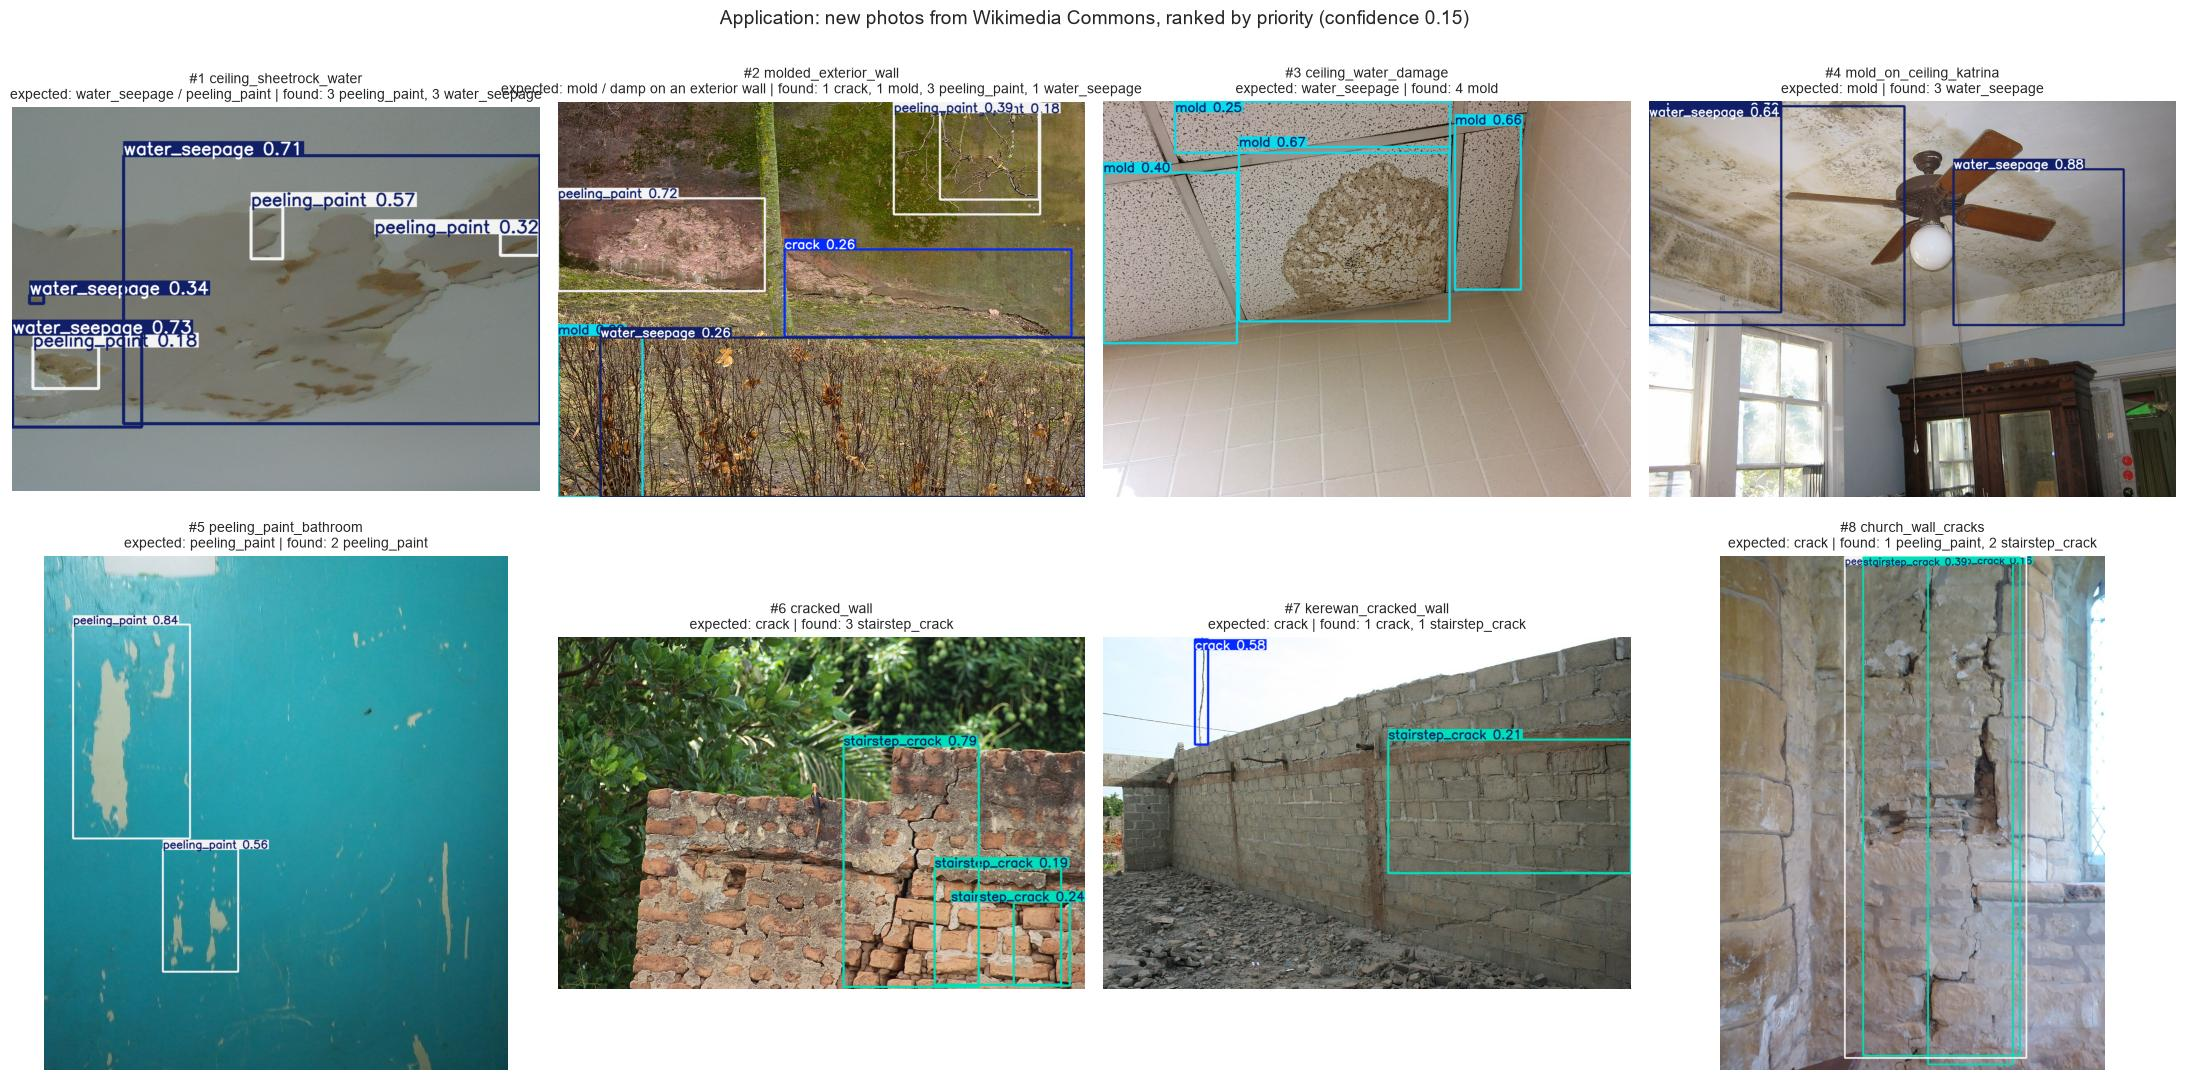

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for ax, (rank, row) in zip(axes.flat, report.iterrows()):
    show_image(plotted[row["photo"]], f"#{rank} {row['photo'][:-4]}\nexpected: {row['expected (from the title)']} | found: {row['detected']}",
               ax, 10)
plt.suptitle(f"Application: new photos from Wikimedia Commons, ranked by priority (confidence {RECOMMENDED_THRESHOLD})", fontsize=14)
plt.tight_layout()
save_fig("12_application", also_to_models="application")
plt.show()

**Reading (8 new photos, no labels, judged by eye):**
- **The ranking is useful:** the photos with the most visible damage (water-stained ceilings, the damp exterior wall, mold on a ceiling) come first; the photos with only cracks come last, because a crack gets one or two boxes.
- **Surface damage is found, but its type is often wrong:** the water-damaged ceilings (#1, #3) get `water_seepage`, `peeling_paint` and `mold` boxes on the right areas, but the stain on the ceiling tiles (#3) is called `mold`, and the black mold of the Katrina ceiling (#4) is called **`water_seepage`** (0.88): the confusion of section 6. The damp exterior wall (#2) gets boxes on the damaged plaster, but also on the hedge in front of it.
- **Cracks in masonry are all called `stairstep_crack`** (#6, #7, #8), even where they are not stepped, and the church wall (#8) also gets `peeling_paint`. In the training data almost every crack in brick or block is a stair-step crack, so the model has learned 'masonry + crack = stair-step crack'. In #7 a pole against the sky is taken for a `crack` (0.58): a thin dark line on a light background.
- **The bathroom wall (#5)** is a clean success: two `peeling_paint` boxes (0.84 and 0.56) on the flaked areas.
- These photos are larger and more varied than the training close-ups. The model finds something relevant in **all 8**: as a pre-screening tool it works; as a judge of the exact defect type it needs a person to check.

## 7.2 Video: the detector on a walk-through

A surveyor often **films** a wall or a room instead of taking single photos. We run the model on three openly licensed videos, none of them related to the dataset:

| Video | What it shows | Why | Author and licence |
|---|---|---|---|
| [A crack on the wall](https://www.pexels.com/video/a-crack-on-the-wall-7830155/) | A slow pan over a cracked white plastered wall | The case the model was trained for: it **should** find the crack | Monstera Production, [Pexels licence](https://www.pexels.com/license/) (free to use and modify) |
| [Broken brick wall](https://www.pexels.com/video/broken-brick-wall-6919174/) | A brick wall with a stepped crack and missing bricks | Masonry: does it recognise a **stair-step crack**? | Kmeel.com Videos, [Pexels licence](https://www.pexels.com/license/) |
| [Water dripping into a bucket in a derelict apartment](https://commons.wikimedia.org/wiki/File:Water_Dripping_into_a_Bucket_in_a_Derelict_Apartment_in_Canada.webm) | A bucket, a wet floor sign, an open ceiling: water damage, but hardly any visible wall defect | A **false-alarm test**: what does the model "see" in a scene it was not trained on? | Gogerr, CC BY 4.0 |

We predict every second frame at the recommended threshold, write an **annotated video** (saved to `models/` and published with the model on Hugging Face, not committed to GitHub), and summarise the detections over time. Every frame is anonymised before it is written.

### From boxes to segmentation masks

A box says **where** a defect is, not its **shape**: a crack box is mostly intact wall. To show the defect itself in the video, every box is turned into a **mask**, with the tool that suits the kind of defect:

| Defect | Segmentation | Why |
|---|---|---|
| `crack`, `stairstep_crack` (thin **lines**) | Inside the YOLO box, the **black-hat filter + Otsu threshold** of our rule-based baseline (notebook 02) keeps the thin dark line | SAM is made for objects and surfaces: given a crack box, it outlines the **wall next to the crack** (we tested it), not the line itself |
| `mold`, `peeling_paint`, `water_seepage` (**surfaces**) | **MobileSAM** (notebook 03, section 10), prompted with the YOLO box | SAM outlines a stain or a patch of mould precisely, with no training |

The rule-based filter alone boxed window frames (section 2); used **only inside boxes the network found**, it becomes a precise crack tracer. The masks also measure the **defect area** (share of the frame), which a box cannot. Each defect is labelled with its name and confidence.

In [26]:
VIDEOS = {    # name: (URL, short description)
    "crack_white_wall": ("https://videos.pexels.com/video-files/7830155/7830155-hd_1920_1080_30fps.mp4", "cracked plastered wall"),
    "brick_wall_step_crack": ("https://videos.pexels.com/video-files/6919174/6919174-hd_1920_1080_30fps.mp4", "brick wall, stepped crack"),
    "derelict_apartment": ("https://upload.wikimedia.org/wikipedia/commons/4/4c/Water_Dripping_into_a_Bucket_in_a_Derelict_Apartment_in_Canada.webm",
                           "derelict apartment (false-alarm test)"),
}
VIDEO_DIR = DATA_DIR / "videos"
VIDEO_DIR.mkdir(exist_ok=True)
for name, (url, _) in VIDEOS.items():
    path = download(url, VIDEO_DIR / f"{name}{Path(url).suffix}")
    print(f"{path.name:>30}: {path.stat().st_size / 1e6:5.1f} MB")


def open_writer(stem, fps, size):
    # H.264 MP4 plays in every browser (and on Hugging Face); fall back to WebM (VP8) or MPEG-4 if H.264 is unavailable
    for suffix, codec in [(".mp4", "avc1"), (".webm", "VP80"), (".mp4", "mp4v")]:
        path = Path(f"{stem}{suffix}")
        writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*codec), fps, size)
        if writer.isOpened():
            return writer, path
    raise RuntimeError("No video codec available")


sam = SAM(attempt_download_asset(str(WEIGHTS_DIR / "mobile_sam.pt")))      # MobileSAM (39 MB), downloaded once
LINE_CLASSES = {CLASS_NAMES.index("crack"), CLASS_NAMES.index("stairstep_crack")}
DISPLAY_NAMES = {"crack": "crack", "mold": "mold", "peeling_paint": "peeling paint",
                 "stairstep_crack": "stair-step crack", "water_seepage": "water seepage"}
MASK_COLORS = {0: (0, 0, 255), 1: (0, 170, 0), 2: (255, 140, 0), 3: (0, 165, 255), 4: (220, 0, 220)}    # BGR


def crack_mask(image, box):
    # Thin dark lines inside a box: black-hat filter + Otsu (the rule-based baseline), keeping only long pieces
    h, w = image.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
    mask = np.zeros((h, w), bool)
    roi = cv2.cvtColor(image[y1:y2, x1:x2], cv2.COLOR_BGR2GRAY)
    if roi.size == 0 or min(roi.shape) < 8:
        return mask
    k = max(9, (min(roi.shape) // 12) | 1)
    blackhat = cv2.morphologyEx(cv2.GaussianBlur(roi, (5, 5), 0), cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    _, lines = cv2.threshold(blackhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    lines = cv2.morphologyEx(lines, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))            # bridge small gaps in the line
    n, labels, stats, _ = cv2.connectedComponentsWithStats(lines)
    keep = [j for j in range(1, n) if max(stats[j, 2], stats[j, 3]) >= 0.10 * max(lines.shape)]
    mask[y1:y2, x1:x2] = np.isin(labels, keep)
    return mask


def defect_masks(image, boxes, classes):
    # One mask per box: crack lines with the black-hat filter, surfaces with SAM (prompted with the YOLO boxes)
    masks = [None] * len(boxes)
    surfaces = [j for j, c in enumerate(classes) if c not in LINE_CLASSES]
    if surfaces:
        sam_result = sam.predict(image, bboxes=boxes[surfaces], device=DEVICE, verbose=False)[0]
        for j, m in zip(surfaces, sam_result.masks.data.cpu().numpy()):
            masks[j] = cv2.resize(m.astype(np.uint8), (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    for j, c in enumerate(classes):
        if c in LINE_CLASSES:
            masks[j] = crack_mask(image, boxes[j])
    return masks


def draw_segmentation(image, boxes, classes, confidences, masks):
    # Coloured masks (lines solid, surfaces semi-transparent), thin boxes, and a readable label per defect
    out = image.copy()
    overlay = image.copy()
    scale = max(image.shape[:2]) / 1280
    for c, m in zip(classes, masks):
        if c in LINE_CLASSES:
            out[cv2.dilate(m.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0] = MASK_COLORS[c]
        else:
            overlay[m] = MASK_COLORS[c]
    out = np.where((overlay != image).any(axis=2, keepdims=True), cv2.addWeighted(overlay, 0.45, out, 0.55, 0), out)
    for (x1, y1, x2, y2), c, p in zip(boxes.astype(int), classes, confidences):
        cv2.rectangle(out, (x1, y1), (x2, y2), MASK_COLORS[c], max(2, int(2 * scale)))
        label = f"{DISPLAY_NAMES[CLASS_NAMES[c]]} {p:.2f}"
        font = 0.9 * scale
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font, max(1, int(2 * scale)))
        ty = y1 if y1 > th + 12 else y1 + th + 12
        cv2.rectangle(out, (x1, ty - th - 12), (x1 + tw + 10, ty), MASK_COLORS[c], -1)
        cv2.putText(out, label, (x1 + 5, ty - 6), cv2.FONT_HERSHEY_SIMPLEX, font, (255, 255, 255), max(1, int(2 * scale)))
    return out


def process_video(name, every=2, max_side=1280):
    # Predict every `every`-th frame, segment each detection, write an annotated video; one row per processed frame
    source = next(VIDEO_DIR.glob(f"{name}.*"))
    capture = cv2.VideoCapture(str(source))
    fps = capture.get(cv2.CAP_PROP_FPS)
    rows, thumbnails, writer, out_path, i = [], {}, None, None, 0
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        if i % every == 0:
            scale = min(1.0, max_side / max(frame.shape[:2]))
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
            result = final.predict(frame, conf=RECOMMENDED_THRESHOLD, device=DEVICE, verbose=False)[0]
            boxes = result.boxes.xyxy.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy().astype(int)
            confidences = result.boxes.conf.cpu().numpy()
            masks = defect_masks(frame, boxes, classes) if len(boxes) else []
            annotated = anonymise(draw_segmentation(frame, boxes, classes, confidences, masks))
            if writer is None:
                writer, out_path = open_writer(MODEL_DIR / f"video_{name}", fps / every, (annotated.shape[1], annotated.shape[0]))
            writer.write(annotated)
            t = i / fps
            area = {c: 0.0 for c in CLASS_NAMES}
            for c in range(len(CLASS_NAMES)):
                class_masks = [m for m, k in zip(masks, classes) if k == c]
                if class_masks:
                    area[CLASS_NAMES[c]] = 100 * np.logical_or.reduce(class_masks).mean()
            rows.append({"video": name, "time (s)": round(t, 2), **{c: int((classes == k).sum()) for k, c in enumerate(CLASS_NAMES)},
                         **{f"{c} area (%)": round(a, 3) for c, a in area.items()},
                         "max confidence": float(confidences.max()) if len(confidences) else 0.0})
            thumbnails[t] = cv2.resize(annotated, None, fx=480 / max(annotated.shape[:2]), fy=480 / max(annotated.shape[:2]))
        i += 1
    capture.release()
    writer.release()
    print(f"{name}: {len(rows)} frames processed ({i / fps:.0f} s of video) -> {out_path.name} ({out_path.stat().st_size / 1e6:.1f} MB)")
    return pd.DataFrame(rows), thumbnails


video_rows, video_thumbnails = [], {}
for name in VIDEOS:
    frame_table, video_thumbnails[name] = process_video(name)
    video_rows.append(frame_table)
video_frames = pd.concat(video_rows, ignore_index=True)

video_summary = video_frames.groupby("video", sort=False).agg(
    frames=("time (s)", "size"), **{f"{c} (% of frames)": (c, lambda s: round(100 * (s > 0).mean())) for c in CLASS_NAMES},
    **{f"{c} mean area (%)": (f"{c} area (%)", lambda s: round(s[s > 0].mean(), 2) if (s > 0).any() else 0.0) for c in CLASS_NAMES},
    **{"mean max confidence": ("max confidence", lambda s: round(s[s > 0].mean(), 2) if (s > 0).any() else 0.0)})
video_summary

          crack_white_wall.mp4:  17.9 MB
     brick_wall_step_crack.mp4:   6.0 MB
       derelict_apartment.webm:   5.2 MB


crack_white_wall: 413 frames processed (28 s of video) -> video_crack_white_wall.mp4 (47.3 MB)


brick_wall_step_crack: 148 frames processed (10 s of video) -> video_brick_wall_step_crack.mp4 (15.9 MB)


derelict_apartment: 291 frames processed (20 s of video) -> video_derelict_apartment.mp4 (30.5 MB)


,frames,crack (% of frames),mold (% of frames),peeling_paint (% of frames),stairstep_crack (% of frames),water_seepage (% of frames),crack mean area (%),mold mean area (%),peeling_paint mean area (%),stairstep_crack mean area (%),water_seepage mean area (%),mean max confidence
video,,,,,,,,,,,,
crack_white_wall,413,100,0,0,0,0,0.71,0.00,0.00,0.00,0.00,0.80
brick_wall_step_crack,148,0,0,0,10,0,0.00,0.00,0.00,2.99,0.00,0.20
derelict_apartment,291,8,1,25,13,9,0.15,4.06,15.65,2.46,19.06,0.36


Figure saved to ..\figures\13_video.png and models/video_frames.png


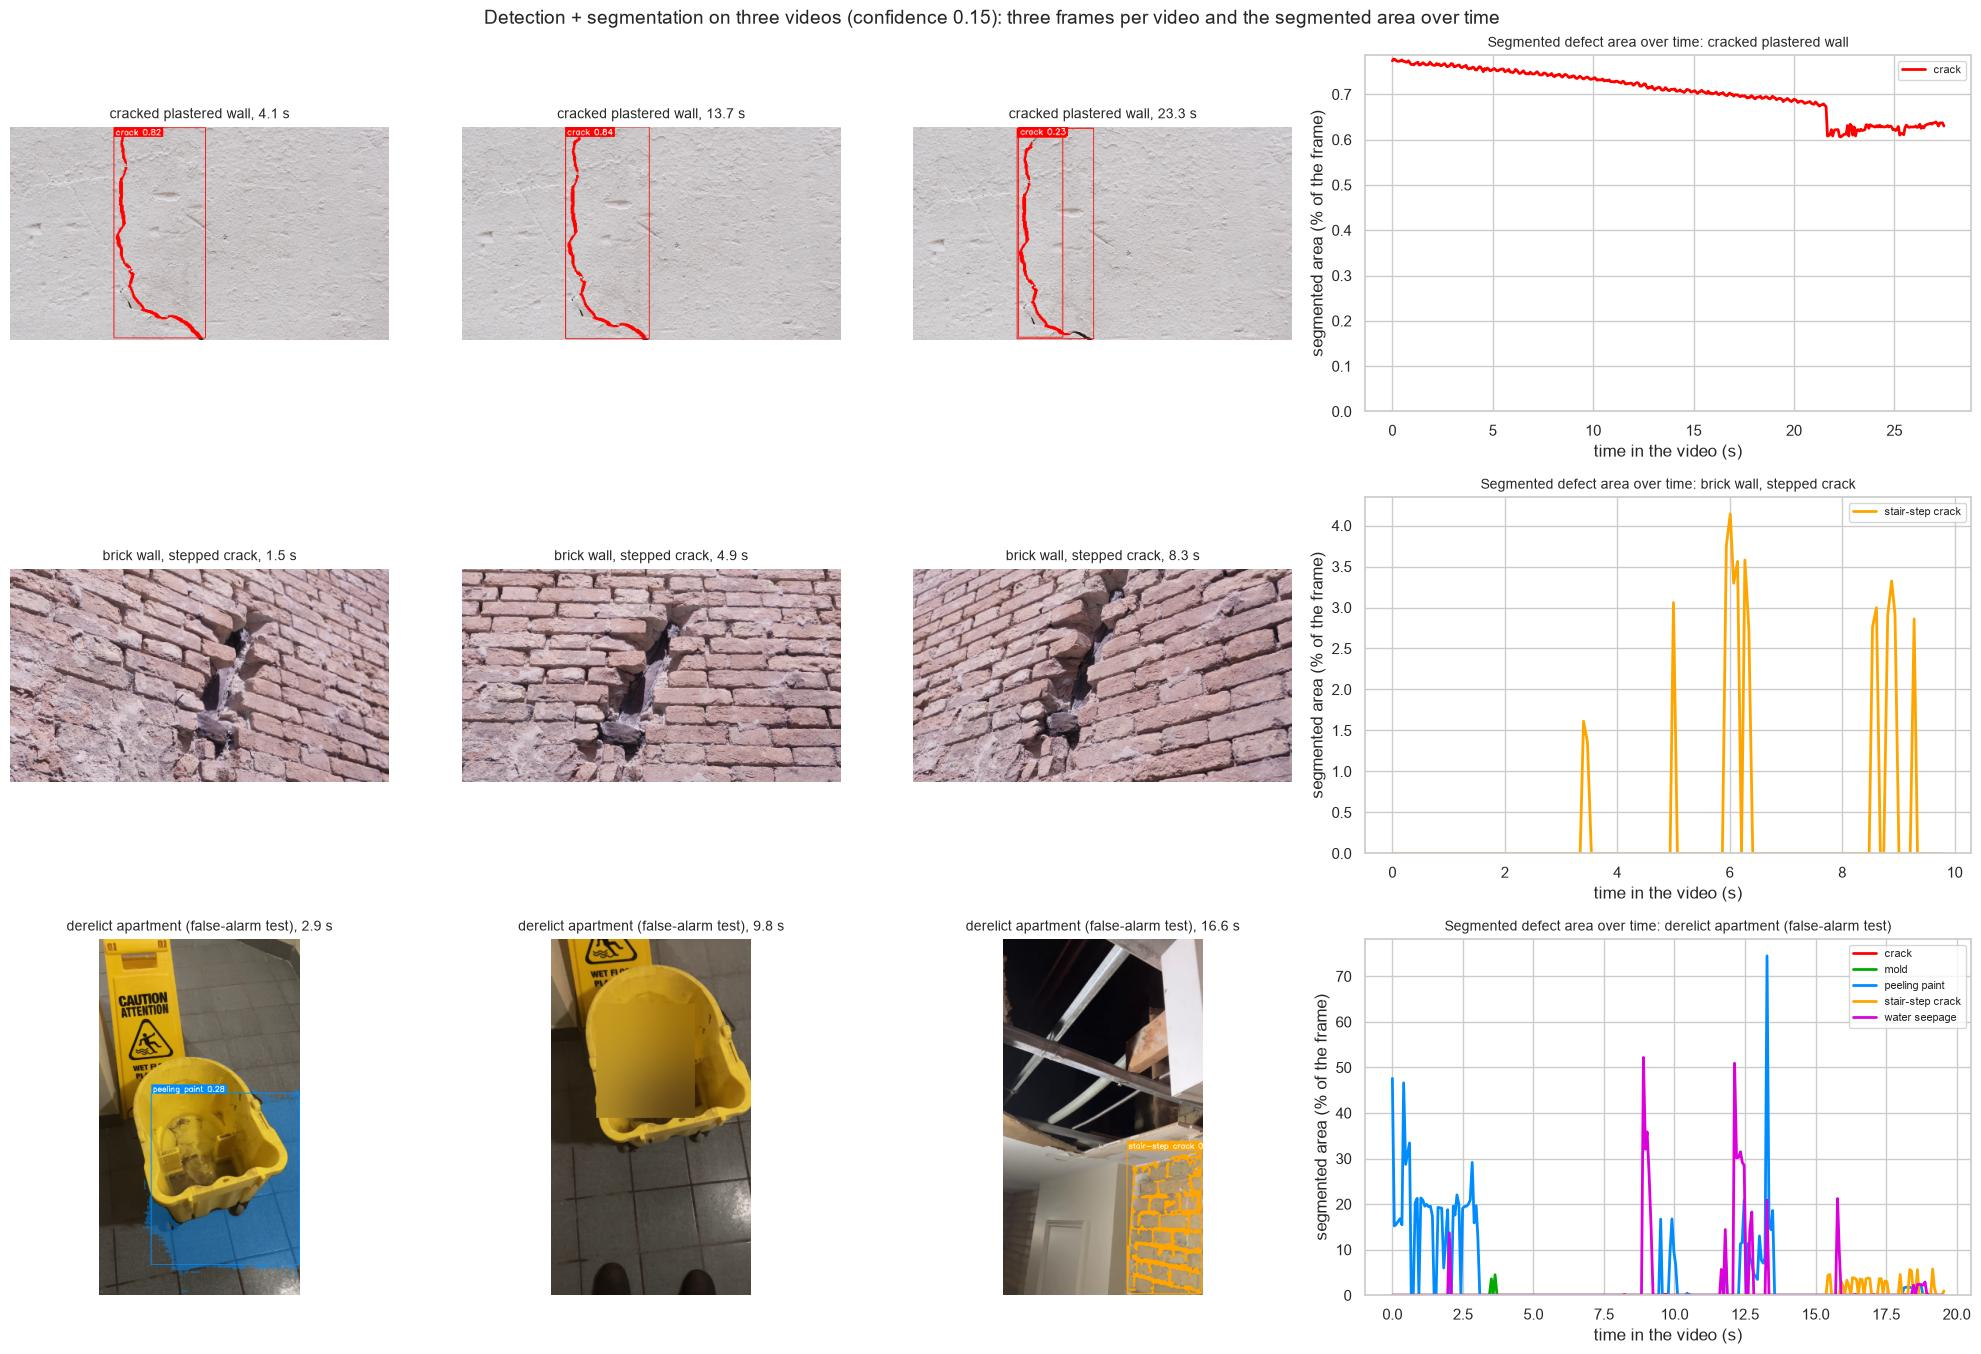

In [27]:
fig, axes = plt.subplots(len(VIDEOS), 4, figsize=(20, 4.6 * len(VIDEOS)), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
for r, (name, (_, description)) in enumerate(VIDEOS.items()):
    times = sorted(video_thumbnails[name])
    for c, q in enumerate([0.15, 0.5, 0.85]):
        t = times[int(q * (len(times) - 1))]
        show_image(video_thumbnails[name][t], f"{description}, {t:.1f} s", axes[r, c], 10)
    part = video_frames[video_frames["video"] == name]
    for k, cls in enumerate(CLASS_NAMES):
        if part[cls].sum():
            color = tuple(v / 255 for v in MASK_COLORS[k][::-1])          # the same colour as the masks in the video
            axes[r, 3].plot(part["time (s)"], part[f"{cls} area (%)"], lw=2, label=DISPLAY_NAMES[cls], color=color)
    axes[r, 3].set_xlabel("time in the video (s)")
    axes[r, 3].set_ylabel("segmented area (% of the frame)")
    axes[r, 3].set_title(f"Segmented defect area over time: {description}", fontsize=10)
    axes[r, 3].set_ylim(bottom=0)
    if axes[r, 3].lines:
        axes[r, 3].legend(fontsize=8, loc="upper right")
    else:
        axes[r, 3].text(0.5, 0.5, "no detections", ha="center", transform=axes[r, 3].transAxes)
plt.suptitle(f"Detection + segmentation on three videos (confidence {RECOMMENDED_THRESHOLD}): three frames per video and the "
             "segmented area over time", fontsize=14)
plt.tight_layout()
save_fig("13_video", also_to_models="video_frames")
plt.show()

**Reading:**
- **Cracked plastered wall (27 s):** the crack is detected in **100 %** of the frames, with a mean confidence of **0.80**, and the line tracer follows it exactly; it covers about 0.7 % of the frame. When the crack starts to leave the image (after about 22 s), the confidence drops to about 0.2 and the box splits in two, but the crack is still found. This is the case the model was trained for, and it works.
- **Brick wall (10 s):** the damage is recognised as `stair-step crack` in only **10 %** of the frames, in short bursts and with a low confidence (about 0.2). The damage here is a hole with missing bricks rather than a thin stepped crack: this kind of masonry damage is not in the training data.
- **Derelict apartment (20 s), the false-alarm test:** there are hardly any wall defects, yet the model reports something in many frames: the water in the mop bucket becomes `peeling paint` (25 % of the frames, with masks covering up to 75 % of the image), stains and shadows become `water seepage` (9 %), and the brick wall at the end `stair-step crack` (13 %). These alarms have a low confidence (mean 0.36), which shows why a threshold and a human check are needed on scenes unlike the training data.
- **Segmentation:** the black-hat line tracer follows thin cracks well, and SAM gives convincing outlines for surfaces, including for the false alarms. A clean mask is **not** a sign that a detection is correct.
- **Privacy:** every frame is anonymised before it is written. In the derelict video the face detector also blurred part of the yellow bucket (a false face): harmless, because for privacy a false blur is better than a missed face.

# 8. Save, reload and use

We copy the selected weights to `models/model.pt` (uploaded to Hugging Face, never committed), together with the training log of the selected run. Then we **reload** the file into a new object and predict one test image, as a user would.

In [28]:
shutil.copy(final_weights, MODEL_DIR / "model.pt")
shutil.copy(final_results_csv, MODEL_DIR / "results.csv")
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

reloaded = YOLO(MODEL_DIR / "model.pt")                    # a new object, loaded from the file only
example_image = str(test_images.iloc[0]["yolo_image"])
result = reloaded.predict(example_image, conf=RECOMMENDED_THRESHOLD, device=DEVICE, verbose=False)[0]
print(f"{Path(example_image).name}: {len(result.boxes)} defect(s):",
      [(reloaded.names[int(c)], round(float(p), 2)) for c, p in zip(result.boxes.cls, result.boxes.conf)])
print("True boxes:", [CLASS_NAMES[c] for c, *_ in test_images.iloc[0]["boxes"]])

Saved: ['README.md', 'application.png', 'class_counts.png', 'confusion_matrix.png', 'dataset_examples.png', 'experiments.csv', 'failures.png', 'model.pt', 'per_class_ap.png', 'predictions_vs_truth.png', 'results.csv', 'threshold_sweep.png', 'training_curves.png', 'video_brick_wall_step_crack.mp4', 'video_crack_white_wall.mp4', 'video_derelict_apartment.mp4', 'video_frames.png']
00185_jpg.rf.8db898723cee79531752417101c62464.jpg: 1 defect(s): [('crack', 0.81)]
True boxes: ['crack']


In [29]:
# Numbers used in the README and the model card
summary = {
    "final_run": FINAL_RUN, "recommended_threshold": RECOMMENDED_THRESHOLD,
    "test_map50": round(test_metrics.box.map50, 3), "test_map50_95": round(test_metrics.box.map, 3),
    "test_precision": round(test_metrics.box.mp, 3), "test_recall": round(test_metrics.box.mr, 3),
    "parameters": sum(p.numel() for p in final.model.parameters()),
    "split_images": images["split"].value_counts().to_dict(), "split_boxes": counts[["train", "val", "test"]].sum().to_dict(),
    "versions": {"torch": torch.__version__, "ultralytics": ultralytics.__version__},
}
print(json.dumps(summary, indent=1, default=str))

{
 "final_run": "yolo26n_640",
 "recommended_threshold": 0.15,
 "test_map50": 0.464,
 "test_map50_95": 0.297,
 "test_precision": 0.524,
 "test_recall": 0.456,
 "parameters": 2535830,
 "split_images": {
  "train": 2060,
  "test": 446,
  "val": 444
 },
 "split_boxes": {
  "train": 2598,
  "val": 569,
  "test": 541
 },
 "versions": {
  "torch": "2.14.1+cu130",
  "ultralytics": "8.4.190"
 }
}


# 9. Conclusions

### Key findings
- **Cracks: good.** On the test set (used once) the model finds **92 % of the cracks** (precision 0.71 at our threshold), with AP50 **0.93**, and stair-step cracks with AP50 **0.77**. The rule-based OpenCV detector finds 45 % (precision 0.41), the pretrained COCO model none.
- **Surface defects: weak.** Mold (AP50 0.29), water seepage (0.28) and peeling paint (0.05) are poorly detected: they have 87–247 training boxes each, and fuzzy, overlapping, inconsistently boxed definitions. The overall test mAP50 is **0.46** (mAP50-95 0.30).
- **Smaller is enough:** the 2.4 M-parameter YOLO26n was as good as the 10 M YOLO26s (validation mAP50-95 0.347 against 0.331), and 320 px images were as good as 640 px: the limit is the data, not the model.
- **Threshold 0.15** (chosen on validation, recall counted twice): **81 %** of all test defects found, with 65 % of the boxes correct. This suits pre-screening, where a missed defect costs more than a false alarm.
- **On new photos and videos** the model finds cracks reliably (100 % of the frames of the crack video) and points to the right areas of water damage, but it confuses the surface classes, calls most masonry cracks 'stair-step', and raises low-confidence false alarms on scenes unlike its training data (a mop bucket as 'peeling paint').
- **From boxes to masks:** combining the detector with a crack-line filter and SAM gives exact outlines and defect areas, useful for documentation; it does not make a wrong detection right.

### Limitations and biases
- **Data:** about 80 % of the images are 200 × 200 px close-ups of single cracks; the other classes come from a few hundred web photos, mostly interior walls and ceilings, some with watermarks of stock-photo and inspection websites. Facades, other materials, climates and building types are under-represented, and almost every image contains a defect, so the model has seen little intact wall.
- **Labels:** the dataset has no written class definitions (we wrote our own, section 1.2); the same kind of defect is sometimes one box and sometimes many; mold, stains and peeling paint overlap. The scores of these classes partly reflect label noise.
- **Small test sets for the rare classes** (21–54 boxes): uncertain by about ±0.1.
- **The split by source** relies on file names and an 8 × 8 image hash; near-duplicates that differ more (for example two crops of one photo) could still sit in different splits, which would make the scores slightly optimistic.
- **Videos and new photos** are few (3 videos, 8 photos) and judged by eye: they illustrate the behaviour, they do not measure it.
- **What the model must not be used for:** a structural safety assessment or any decision without a qualified person checking (it says nothing about the width, depth or cause of a crack); legal, insurance or sale decisions about a property; monitoring people. 'No detection' means 'not found', never 'no defect'.